# ListingLens: room type, photo quality and amenity tags for listing photos

*Project 1 of a series of computer-vision projects for real-estate marketplaces. Code, app and results: [repository README](../README.md).*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/elshahedmohamed1998-ux/listinglens/blob/main/notebooks/01_listinglens.ipynb)

Property marketplaces receive thousands of listing photos a day from developers and brokers, in every quality. Buyers judge a home by those photos, and search filters depend on knowing what each photo shows. ListingLens takes one photo and returns:

1. **Room type**: bathroom, bedroom, dining room, kitchen or living room
2. **Photo quality**: a 0–100 score with a reason (too blurry, too dark, ...)
3. **Amenity tags**: balcony, open kitchen, sea view, pool, ... (zero-shot, no labels needed)
4. **Cover photo**: the best first photo for a listing

### Results at a glance (test set, 788 unseen photos)

| Model | Method | Test accuracy | Test macro-F1 | Training |
|---|---|---|---|---|
| SigLIP ViT-B-16 | zero-shot | 0.952 | 0.954 | none |
| CLIP ViT-L-14 | zero-shot | 0.949 | 0.951 | none |
| CLIP ViT-B-32 | zero-shot | 0.947 | 0.950 | none |
| **CLIP ViT-B-32 + logistic regression** ✅ | linear probe | **0.944** | **0.946** | 1.9 s |
| ResNet-18 (ImageNet) | fine-tune | 0.891 | 0.893 | 8.3 min |

✅ = chosen on the **validation** set and used in the demo.

**Key findings**
- The four CLIP-style models are statistically tied (within 0.008, about 6 images). I kept the cheapest one instead of chasing the test-set leader.
- A frozen foundation model beats fine-tuning here: ResNet-18 trained for 12 epochs stays ~5 points behind CLIP + logistic regression.
- Most remaining errors are photos that show **two rooms** (open-plan living + dining, kitchen + dining), plus label noise: some photos appear in the dataset twice with different labels.
- A simple, explainable quality score (Laplacian sharpness, brightness, contrast) flagged all 10 deliberately blurred or darkened photos.

### Contents
0. Setup and data · 1. Explore the data · 2. Split · 3. Zero-shot CLIP · 4. Linear probe · 5. Fine-tuning ResNet-18 · 6. Test evaluation and error analysis · 7. Photo quality score · 8. Amenity tags · 9. Cover photo picker · 10. Saving and reproducibility · 11. Gradio demo · Conclusions · Appendix: key terms

---
## 0. Setup and data

Runs on Google Colab with a free T4 GPU (**Runtime → Change runtime type → T4 GPU**).

**Dataset:** [House Rooms Image Dataset](https://www.kaggle.com/datasets/robinreni/house-rooms-image-dataset) on Kaggle: 5,250 photos of bathrooms, bedrooms, dining rooms, kitchens and living rooms. It is downloaded at run time and not stored in this repository.

**Kaggle access:** create an API token on kaggle.com (**Settings → API → Create New Token**), then add two Colab secrets (🔑 icon in the left sidebar), `KAGGLE_USERNAME` and `KAGGLE_KEY`, with notebook access switched on. The key never appears in the notebook.

Every result (tables, embeddings, models, figures) is saved to Google Drive, so work survives a Colab disconnect.

In [ ]:
# 0.3a: install the Kaggle download helper (already on most Colab images; this makes sure it is current)
!pip -q install --upgrade kagglehub

In [ ]:
# 0.3b: read your Kaggle credentials from Colab Secrets
import os

try:
    from google.colab import userdata
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
    print("Kaggle credentials loaded from Colab Secrets.")
except Exception as e:
    print(f"Could not read Colab Secrets ({type(e).__name__}).")
    print("Public datasets often download anyway. If the next cell fails, finish task 0.2 and run this cell again.")

Kaggle credentials loaded from Colab Secrets.


In [ ]:
# 0.3c: download the dataset and show what is inside
import kagglehub
from pathlib import Path

DATA_ROOT = Path(kagglehub.dataset_download("robinreni/house-rooms-image-dataset"))
print("Dataset downloaded to:", DATA_ROOT, "\n")

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
total = 0
for folder in sorted(p for p in DATA_ROOT.rglob("*") if p.is_dir()):
    n_images = sum(1 for f in folder.iterdir() if f.suffix.lower() in IMAGE_EXTS)
    total += n_images
    print(f"{str(folder.relative_to(DATA_ROOT)) + '/':45s} {n_images:6d} images")
print(f"\nTotal images: {total}")

Extracting files...
Dataset downloaded to: /root/.cache/kagglehub/datasets/robinreni/house-rooms-image-dataset/versions/1 

House_Room_Dataset/                                0 images
House_Room_Dataset/Bathroom/                     606 images
House_Room_Dataset/Bedroom/                     1248 images
House_Room_Dataset/Dinning/                     1158 images
House_Room_Dataset/Kitchen/                      965 images
House_Room_Dataset/Livingroom/                  1273 images

Total images: 5250


One folder per room type. Folder names are the labels, so the dataset's misspelled `Dinning` stays in code and is shown as "dining room" wherever a person reads it.

In [ ]:
# 0.4 Mount Google Drive and create the output folder
from google.colab import drive
from pathlib import Path

# 1. Connect your Google Drive to this Colab session.
#    A pop-up asks you to choose your Google account and allow access.
drive.mount("/content/drive")

# 2. The folder where every result from this project will be saved.
OUT_DIR = Path("/content/drive/MyDrive/proptech-vision/listinglens")

# 3. Create it. parents=True also creates any missing parent folders;
#    exist_ok=True means re-running this cell won't raise an error.
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Saving results to:", OUT_DIR)
print("Folder exists:", OUT_DIR.exists())

Mounted at /content/drive
Saving results to: /content/drive/MyDrive/proptech-vision/listinglens
Folder exists: True


---
## 1. Explore the data

Before training anything: a table of every image, class balance, a look at the photos, and checks for sizes, colour modes and broken files.

In [ ]:
# 1.1 Table of image paths and labels
import pandas as pd

# 1. Find every image file inside the dataset folder, at any depth.
#    rglob("*") walks through all subfolders; we keep only files with an image extension.
image_paths = sorted(
    p for p in DATA_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)

# 2. Build one row per image: the full path, and the folder it sits in as its label.
#    p.parent is the folder containing the file; .name is just the folder's name (e.g. "Kitchen").
df = pd.DataFrame({
    "path":  [str(p) for p in image_paths],
    "label": [p.parent.name for p in image_paths],
})

# 3. Look at the result.
print("Number of images:", len(df))
print("Classes:", sorted(df["label"].unique()))
df.head()

Number of images: 5250
Classes: ['Bathroom', 'Bedroom', 'Dinning', 'Kitchen', 'Livingroom']


,path,label
0,/root/.cache/kagglehub/datasets/robinreni/hous...,Bathroom
1,/root/.cache/kagglehub/datasets/robinreni/hous...,Bathroom
2,/root/.cache/kagglehub/datasets/robinreni/hous...,Bathroom
3,/root/.cache/kagglehub/datasets/robinreni/hous...,Bathroom
4,/root/.cache/kagglehub/datasets/robinreni/hous...,Bathroom


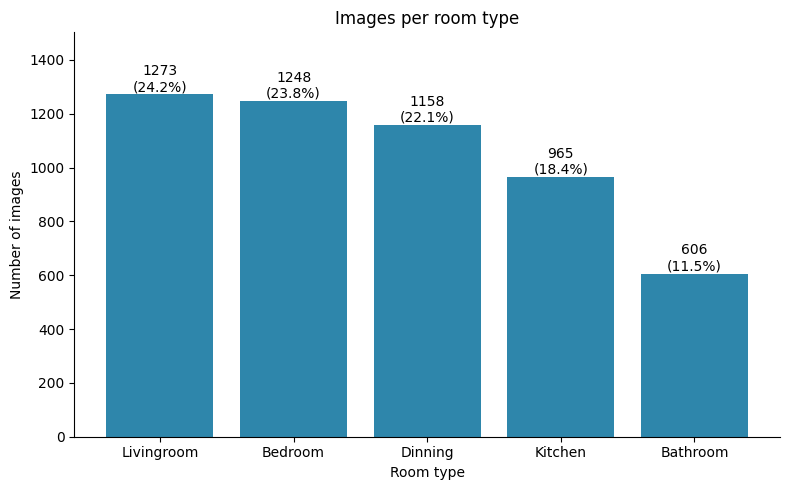

            images  percent
label                      
Livingroom    1273     24.2
Bedroom       1248     23.8
Dinning       1158     22.1
Kitchen        965     18.4
Bathroom       606     11.5

Largest / smallest class ratio: 2.10


In [ ]:
# 1.2 Images per class
import matplotlib.pyplot as plt

# 1. Count images per class, largest first, and turn counts into percentages.
counts = df["label"].value_counts()
percents = counts / counts.sum() * 100

# 2. Draw the bar chart.
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(counts.index, counts.values, color="#2E86AB")

# 3. Write "count (percent%)" on top of each bar.
for bar, n, pct in zip(bars, counts.values, percents.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,  # horizontal centre of the bar
        bar.get_height(),                   # top of the bar
        f"{n}\n({pct:.1f}%)",
        ha="center", va="bottom", fontsize=10,
    )

ax.set_title("Images per room type")
ax.set_xlabel("Room type")
ax.set_ylabel("Number of images")
ax.set_ylim(0, counts.max() * 1.18)  # leave space above the tallest bar for its label
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

# 4. Save the chart to Drive for the README, then show it.
plt.savefig(OUT_DIR / "class_counts.png", dpi=200, bbox_inches="tight")
plt.show()

# 5. Measure the balance: how many times bigger is the largest class than the smallest?
ratio = counts.max() / counts.min()
print(counts.to_frame("images").assign(percent=percents.round(1)))
print(f"\nLargest / smallest class ratio: {ratio:.2f}")

**Class balance:** living room and bedroom have about twice as many photos as bathroom (ratio 2.10). So every split is **stratified** by class, and models are compared with **macro-F1**, which weights each room type equally.

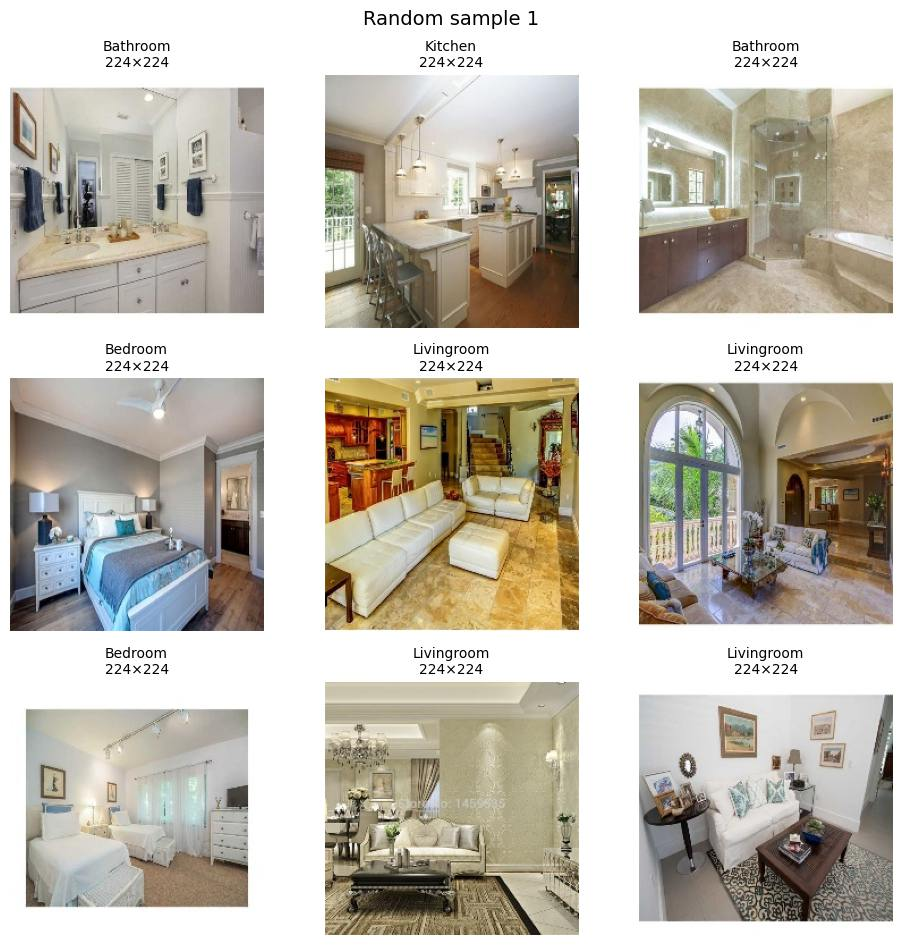

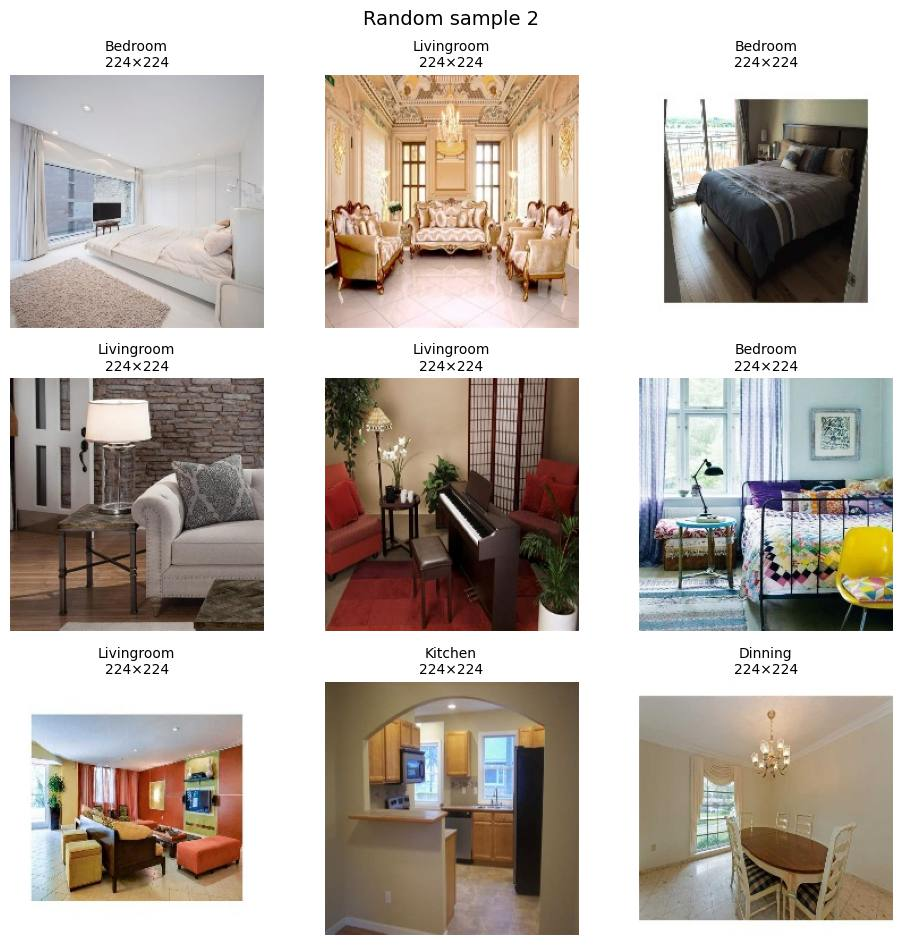

In [ ]:
# 1.3 Two random 3 × 3 samples
import matplotlib.pyplot as plt
from PIL import Image

def show_grid(data, n_rows=3, n_cols=3, seed=None, title=None, save_as=None):
    """Show a grid of random images from `data`, with each image's label as its title."""
    # Pick random rows. A fixed seed gives the same sample every time; seed=None gives a new one each run.
    sample = data.sample(n=n_rows * n_cols, random_state=seed)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3.2, n_rows * 3.2))
    for ax, (_, row) in zip(axes.flat, sample.iterrows()):
        img = Image.open(row["path"]).convert("RGB")  # convert so greyscale/transparent images display correctly
        ax.imshow(img)
        ax.set_title(f"{row['label']}\n{img.width}×{img.height}", fontsize=10)
        ax.axis("off")  # hide the pixel axes; they add nothing here

    if title:
        fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    if save_as:
        plt.savefig(OUT_DIR / save_as, dpi=150, bbox_inches="tight")
    plt.show()

# Sample 1 and sample 2: different seeds, so different images.
show_grid(df, seed=1, title="Random sample 1", save_as="sample_grid_1.png")
show_grid(df, seed=2, title="Random sample 2", save_as="sample_grid_2.png")

**Spot check:** the labels look right, but one photo carries a **watermark**. That matters twice: a model can learn a watermark as a shortcut for a class, and watermarked or contact-stamped photos are a real moderation problem for listing platforms (the subject of project 02). The next cells locate it and start a list of flagged images.

In [ ]:
# 1.3b Locate the watermarked photo: same seed = same 9 images in the same order
GRID_SEED = 1  # the first grid
sample = df.sample(n=9, random_state=GRID_SEED)
for i, (_, row) in enumerate(sample.iterrows()):
    print(f"row {i // 3 + 1}, col {i % 3 + 1}  |  {row['label']:12s} | {row['path']}")

row 1, col 1  |  Bathroom     | /root/.cache/kagglehub/datasets/robinreni/house-rooms-image-dataset/versions/1/House_Room_Dataset/Bathroom/bath_1004.jpg
row 1, col 2  |  Kitchen      | /root/.cache/kagglehub/datasets/robinreni/house-rooms-image-dataset/versions/1/House_Room_Dataset/Kitchen/kitchen_1284.jpg
row 1, col 3  |  Bathroom     | /root/.cache/kagglehub/datasets/robinreni/house-rooms-image-dataset/versions/1/House_Room_Dataset/Bathroom/bath_703.jpg
row 2, col 1  |  Bedroom      | /root/.cache/kagglehub/datasets/robinreni/house-rooms-image-dataset/versions/1/House_Room_Dataset/Bedroom/bed_549.jpg
row 2, col 2  |  Livingroom   | /root/.cache/kagglehub/datasets/robinreni/house-rooms-image-dataset/versions/1/House_Room_Dataset/Livingroom/living_1375.jpg
row 2, col 3  |  Livingroom   | /root/.cache/kagglehub/datasets/robinreni/house-rooms-image-dataset/versions/1/House_Room_Dataset/Livingroom/living_545.jpg
row 3, col 1  |  Bedroom      | /root/.cache/kagglehub/datasets/robinreni/hou

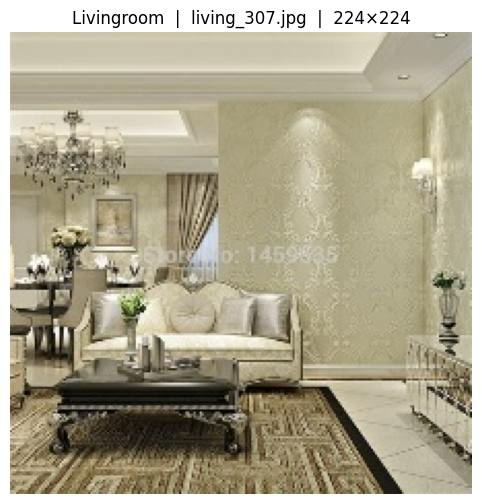

In [ ]:
# 1.3c Enlarge it
ROW, COL = 3, 2  # position of the watermarked image in the grid

row = sample.iloc[(ROW - 1) * 3 + (COL - 1)]
img = Image.open(row["path"]).convert("RGB")

plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.title(f"{row['label']}  |  {Path(row['path']).name}  |  {img.width}×{img.height}")
plt.axis("off")
plt.show()

In [ ]:
# 1.3d Record it in a list of flagged images (row 3, column 2 of the first grid)
ROW, COL = 3, 2
row = sample.iloc[(ROW - 1) * 3 + (COL - 1)]

# Make a list with one note about this image
flagged = [
    {"path": row["path"], "label": row["label"], "issue": "watermark"},
]

# Turn the list into a table, save it to Drive, and show it
flagged_df = pd.DataFrame(flagged)
flagged_df.to_csv(OUT_DIR / "flagged_images.csv", index=False)
flagged_df

,path,label,issue
0,/root/.cache/kagglehub/datasets/robinreni/hous...,Livingroom,watermark


In [ ]:
# 1.4 Open every image: size, colour mode, broken files
from tqdm.auto import tqdm  # progress bar
from PIL import Image

widths, heights, modes = [], [], []
broken = []  # files that fail to open

for path in tqdm(df["path"], desc="Opening images"):
    try:
        with Image.open(path) as img:
            img.load()  # actually read all the pixels; this is what catches damaged files
            widths.append(img.width)
            heights.append(img.height)
            modes.append(img.mode)
    except Exception as e:
        widths.append(None)
        heights.append(None)
        modes.append(None)
        broken.append({"path": path, "error": f"{type(e).__name__}: {e}"})

df["width"] = widths
df["height"] = heights
df["mode"] = modes

print(f"Opened {len(df) - len(broken)} of {len(df)} images.")
print(f"Broken files: {len(broken)}")
for b in broken:
    print("  ", b["path"], "→", b["error"])

print("\nImage modes:")
print(df["mode"].value_counts(dropna=False))

df.head()

Opened 5250 of 5250 images.
Broken files: 0

Image modes:
mode
RGB    5250
Name: count, dtype: int64


,path,label,width,height,mode
0,/root/.cache/kagglehub/datasets/robinreni/hous...,Bathroom,224,224,RGB
1,/root/.cache/kagglehub/datasets/robinreni/hous...,Bathroom,224,224,RGB
2,/root/.cache/kagglehub/datasets/robinreni/hous...,Bathroom,224,224,RGB
3,/root/.cache/kagglehub/datasets/robinreni/hous...,Bathroom,224,224,RGB
4,/root/.cache/kagglehub/datasets/robinreni/hous...,Bathroom,224,224,RGB


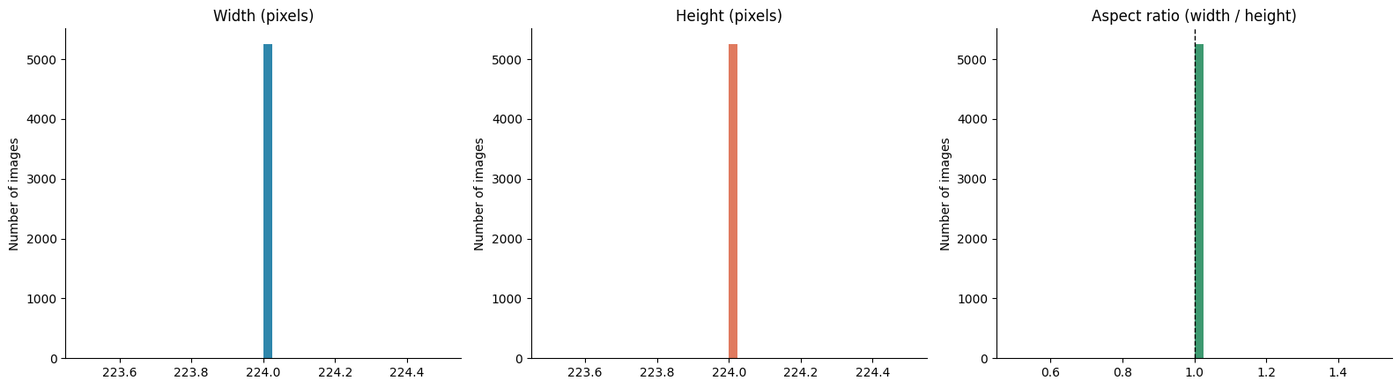

        width  height
count  5250.0  5250.0
mean    224.0   224.0
std       0.0     0.0
min     224.0   224.0
25%     224.0   224.0
50%     224.0   224.0
75%     224.0   224.0
max     224.0   224.0

Images with shorter side under 224 px: 0

Images that are not RGB: 0 of 5250
Series([], Name: count, dtype: int64)


In [ ]:
# 1.5 Sizes, aspect ratio and colour modes
ok = df.dropna(subset=["width", "height"])  # only images that opened

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].hist(ok["width"], bins=40, color="#2E86AB")
axes[0].set_title("Width (pixels)")

axes[1].hist(ok["height"], bins=40, color="#E07A5F")
axes[1].set_title("Height (pixels)")

# Aspect ratio = width / height. 1.0 is square, above 1 is landscape, below 1 is portrait.
axes[2].hist(ok["width"] / ok["height"], bins=40, color="#3D9970")
axes[2].axvline(1.0, color="black", linestyle="--", linewidth=1)
axes[2].set_title("Aspect ratio (width / height)")

for ax in axes:
    ax.set_ylabel("Number of images")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT_DIR / "image_sizes.png", dpi=200, bbox_inches="tight")
plt.show()

# Summary numbers
print(ok[["width", "height"]].describe().round(0))

short_side = ok[["width", "height"]].min(axis=1)
print(f"\nImages with shorter side under 224 px: {(short_side < 224).sum()}")

# Non-RGB images
not_rgb = ok[ok["mode"] != "RGB"]
print(f"\nImages that are not RGB: {len(not_rgb)} of {len(ok)}")
print(not_rgb["mode"].value_counts())

In [ ]:
# 1.6 Drop broken files and save the clean table
n_before = len(df)

# Keep only rows where the image opened (width is not empty)
df = df.dropna(subset=["width", "height"]).reset_index(drop=True)
df["width"] = df["width"].astype(int)
df["height"] = df["height"].astype(int)

n_removed = n_before - len(df)
print(f"Removed {n_removed} broken files. {len(df)} images left.")

# Save the clean table; every later step starts from this file
df.to_csv(OUT_DIR / "images_clean.csv", index=False)
print("Saved:", OUT_DIR / "images_clean.csv")

Removed 0 broken files. 5250 images left.
Saved: /content/drive/MyDrive/proptech-vision/listinglens/images_clean.csv


**Findings from the data**
1. **All 5,250 images are exactly 224 × 224 RGB** (standard deviation 0). The creator resized them, so original aspect ratios are lost and fine details such as small watermarks or text are hard to see. Real listing photos are larger and rarely square, so expect a gap between this dataset and real uploads.
2. **No broken files:** every image opened and decoded fully.
3. **Moderate imbalance** (ratio 2.10): stratified splits and macro-F1.
4. **At least one watermarked photo** (`living_307.jpg`), kept because real listings contain watermarks too, and flagged for the error analysis.

---
## 2. Train / validation / test split

70 / 15 / 15, stratified by class, fixed seed (42). The **validation** set is used for every decision (prompt, model, regularisation). The **test** set is used once, in section 6.

In [ ]:
# 2.1 Stratified 70/15/15 split, saved to Drive
from sklearn.model_selection import train_test_split

SEED = 42  # fixed seed: the split is identical every time you run this

# 2.1a: split off the test set (15% of all images)
train_val_df, test_df = train_test_split(
    df,
    test_size=0.15,
    stratify=df["label"],  # keep the class proportions the same in both parts
    random_state=SEED,
)

# 2.1b: split the remaining 85% into train and validation.
# Validation should be 15% of ALL images, which is 0.15 / 0.85 ≈ 17.6% of what's left.
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.15 / 0.85,
    stratify=train_val_df["label"],
    random_state=SEED,
)

# Renumber rows 0, 1, 2… in each table
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# 2.2: images per class in each split, with percentages
split_counts = pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "val":   val_df["label"].value_counts(),
    "test":  test_df["label"].value_counts(),
})
split_counts.loc["TOTAL"] = split_counts.sum()
print("Images per class:")
print(split_counts)

print("\nPercentage of each split that is each class:")
print((split_counts.drop("TOTAL") / split_counts.loc["TOTAL"] * 100).round(1))

total = len(df)
print(f"\nSplit sizes: train {len(train_df)} ({len(train_df)/total:.0%}), "
      f"val {len(val_df)} ({len(val_df)/total:.0%}), "
      f"test {len(test_df)} ({len(test_df)/total:.0%})")

# Safety check: no image may appear in two splits
assert not set(train_df["path"]) & set(val_df["path"]), "train and val overlap!"
assert not set(train_df["path"]) & set(test_df["path"]), "train and test overlap!"
assert not set(val_df["path"]) & set(test_df["path"]), "val and test overlap!"
print("No overlap between splits ✔")

# 2.3: save to Drive
train_df.to_csv(OUT_DIR / "train.csv", index=False)
val_df.to_csv(OUT_DIR / "val.csv", index=False)
test_df.to_csv(OUT_DIR / "test.csv", index=False)
print("Saved train.csv, val.csv, test.csv to", OUT_DIR)

Images per class:
            train  val  test
label                       
Livingroom    891  191   191
Bedroom       874  187   187
Dinning       810  174   174
Kitchen       675  145   145
Bathroom      424   91    91
TOTAL        3674  788   788

Percentage of each split that is each class:
            train   val  test
label                        
Livingroom   24.3  24.2  24.2
Bedroom      23.8  23.7  23.7
Dinning      22.0  22.1  22.1
Kitchen      18.4  18.4  18.4
Bathroom     11.5  11.5  11.5

Split sizes: train 3674 (70%), val 788 (15%), test 788 (15%)
No overlap between splits ✔
Saved train.csv, val.csv, test.csv to /content/drive/MyDrive/proptech-vision/listinglens


---
## 3. Baseline A: zero-shot room classification with CLIP

[CLIP](https://github.com/mlfoundations/open_clip) learned from billions of images and their captions, so it maps a photo and a sentence into the same vector space: a photo of a kitchen lands close to the sentence *"a photo of a kitchen"*. That allows classification **without any training**: encode one sentence per room, encode the photo, pick the closest sentence (cosine similarity).

Setup: `open_clip`, `ViT-B-32` with `laion2b_s34b_b79k` weights (151M parameters, trained on 2 billion image–text pairs), the model's own preprocessing, inference only (`eval()` + `no_grad()`).

In [ ]:
!pip -q install open_clip_torch

In [ ]:
# 3.1 Load CLIP ViT-B-32 and its preprocessing
import torch
import open_clip
import pandas as pd
from pathlib import Path
from PIL import Image

# If Colab restarted, reload the splits from Drive (needs the Drive cell from 0.5 run first)
if "OUT_DIR" not in globals():
    OUT_DIR = Path("/content/drive/MyDrive/proptech-vision/listinglens")
print("Using folder:", OUT_DIR)

if "train_df" not in globals():
    train_df = pd.read_csv(OUT_DIR / "train.csv")
    val_df = pd.read_csv(OUT_DIR / "val.csv")
    test_df = pd.read_csv(OUT_DIR / "test.csv")
    print("Reloaded splits from Drive.")

# 1. Use the GPU if there is one
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# 2. Load the model, its image preprocessing, and its text tokenizer
MODEL_NAME = "ViT-B-32"
PRETRAINED = "laion2b_s34b_b79k"
model, _, preprocess = open_clip.create_model_and_transforms(MODEL_NAME, pretrained=PRETRAINED)
tokenizer = open_clip.get_tokenizer(MODEL_NAME)

# 3. Move the model to the GPU and switch to evaluation mode (we use it, we don't train it)
model = model.to(device).eval()

# 4. Checks
n_params = sum(p.numel() for p in model.parameters())
print(f"Model: {MODEL_NAME} ({PRETRAINED}), {n_params / 1e6:.0f} million parameters")
print("\nPreprocessing steps:\n", preprocess)

with torch.no_grad():
    img = preprocess(Image.open(val_df.loc[0, "path"]).convert("RGB")).unsqueeze(0).to(device)
    emb = model.encode_image(img)
print("\nOne image →", tuple(img.shape), "→ embedding of shape", tuple(emb.shape))

Using folder: /content/drive/MyDrive/proptech-vision/listinglens
Device: cuda
Model: ViT-B-32 (laion2b_s34b_b79k), 151 million parameters

Preprocessing steps:
 Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeConvertMode()
    MaybeToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)

One image → (1, 3, 224, 224) → embedding of shape (1, 512)


In [ ]:
# 3.2 One prompt per class, encoded and normalised
# 1. The classes, exactly as the folder names (these are the labels in train/val/test)
CLASSES = sorted(train_df["label"].unique())
print("Classes:", CLASSES)

# 2. Clean, human words for each class (the dataset spells "Dinning" with two n's)
CLASS_NAMES = {
    "Bathroom":   "bathroom",
    "Bedroom":    "bedroom",
    "Dinning":    "dining room",
    "Kitchen":    "kitchen",
    "Livingroom": "living room",
}

# 3. One prompt per class, built from a template
TEMPLATE = "a photo of a {}."
prompts = [TEMPLATE.format(CLASS_NAMES[c]) for c in CLASSES]
for c, p in zip(CLASSES, prompts):
    print(f"{c:12s} → {p}")

# 4. Encode the prompts and normalise them to length 1
def encode_prompts(prompt_list):
    with torch.no_grad():
        tokens = tokenizer(prompt_list).to(device)
        emb = model.encode_text(tokens)
        emb = emb / emb.norm(dim=-1, keepdim=True)
    return emb

text_emb = encode_prompts(prompts)
print("\nText embeddings shape:", tuple(text_emb.shape))   # (5, 512): one vector per class
print("Vector lengths:", text_emb.norm(dim=-1).round(decimals=3).tolist())  # all should be 1.0

Classes: ['Bathroom', 'Bedroom', 'Dinning', 'Kitchen', 'Livingroom']
Bathroom     → a photo of a bathroom.
Bedroom      → a photo of a bedroom.
Dinning      → a photo of a dining room.
Kitchen      → a photo of a kitchen.
Livingroom   → a photo of a living room.

Text embeddings shape: (5, 512)
Vector lengths: [1.0, 1.0, 1.0, 1.0, 1.0]


In [ ]:
# 3.3 Encode the validation images in batches
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
import numpy as np

class ImageDataset(Dataset):
    """Gives the model one preprocessed image at a time, from a list of file paths."""
    def __init__(self, paths):
        self.paths = list(paths)
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return preprocess(Image.open(self.paths[i]).convert("RGB"))

def encode_images(paths, batch_size=128):
    """Encode images in batches. Returns normalised embeddings, one row per image."""
    loader = DataLoader(ImageDataset(paths), batch_size=batch_size, num_workers=2)
    all_emb = []
    with torch.no_grad():
        for images in tqdm(loader, desc="Encoding images"):
            emb = model.encode_image(images.to(device))
            emb = emb / emb.norm(dim=-1, keepdim=True)  # length 1, like the text embeddings
            all_emb.append(emb.cpu())                   # move to CPU so GPU memory doesn't fill up
    return torch.cat(all_emb)

val_emb = encode_images(val_df["path"])
print("Validation embeddings:", tuple(val_emb.shape))  # (number of val images, 512)

# Save them so you don't have to recompute (Step 4 will reuse them)
np.save(OUT_DIR / "val_emb.npy", val_emb.numpy())

Validation embeddings: (788, 512)


In [ ]:
# 3.4 Zero-shot prediction = the most similar prompt
# 1. Similarity between every image and every prompt
#    (N images × 512) @ (512 × 5 prompts) = (N × 5): one score per image per class
sims = val_emb @ text_emb.cpu().T
print("Similarity matrix:", tuple(sims.shape))

# 2. The prediction is the class with the highest similarity
pred_idx = sims.argmax(dim=1).numpy()

# 3. Turn positions (0–4) back into class names and add them to a copy of the table
val_results = val_df.copy()
val_results["pred"] = [CLASSES[i] for i in pred_idx]
val_results["confidence"] = (100 * sims).softmax(dim=1).max(dim=1).values.numpy().round(3)
val_results["correct"] = val_results["pred"] == val_results["label"]

print(f"Correct on {val_results['correct'].sum()} of {len(val_results)} validation images")
val_results[["label", "pred", "confidence", "correct"]].head(10)

Similarity matrix: (788, 5)
Correct on 739 of 788 validation images


,label,pred,confidence,correct
0,Livingroom,Livingroom,0.987,True
1,Bathroom,Bathroom,1.000,True
2,Kitchen,Kitchen,0.999,True
3,Dinning,Dinning,0.999,True
4,Bathroom,Bathroom,1.000,True
5,Bedroom,Bedroom,0.991,True
6,Livingroom,Dinning,0.900,False
7,Kitchen,Kitchen,1.000,True
8,Dinning,Dinning,0.998,True
9,Kitchen,Kitchen,0.830,True


In [ ]:
# 3.5 Validation accuracy and macro-F1
from sklearn.metrics import accuracy_score, f1_score, classification_report

y_true = val_results["label"]
y_pred = val_results["pred"]

acc = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")

print(f"Zero-shot CLIP ({MODEL_NAME}, template: '{TEMPLATE}')")
print(f"  Accuracy: {acc:.3f}")
print(f"  Macro-F1: {macro_f1:.3f}\n")

# Precision, recall and F1 for each class
print(classification_report(y_true, y_pred, digits=3))

# Keep a log of every experiment, so you can compare them later (3.6, Step 4, Step 5)
if "experiments" not in globals():
    experiments = []
experiments.append({
    "method": "zero-shot",
    "model": f"{MODEL_NAME} / {PRETRAINED}",
    "template": TEMPLATE,
    "val_accuracy": round(acc, 3),
    "val_macro_f1": round(macro_f1, 3),
})
pd.DataFrame(experiments).to_csv(OUT_DIR / "experiments.csv", index=False)
pd.DataFrame(experiments)

Zero-shot CLIP (ViT-B-32, template: 'a photo of a {}.')
  Accuracy: 0.938
  Macro-F1: 0.939

              precision    recall  f1-score   support

    Bathroom      0.948     1.000     0.973        91
     Bedroom      0.984     0.995     0.989       187
     Dinning      0.875     0.925     0.899       174
     Kitchen      0.926     0.862     0.893       145
  Livingroom      0.957     0.921     0.939       191

    accuracy                          0.938       788
   macro avg      0.938     0.941     0.939       788
weighted avg      0.938     0.938     0.938       788


,method,model,template,val_accuracy,val_macro_f1
0,zero-shot,ViT-B-32 / laion2b_s34b_b79k,a photo of a {}.,0.938,0.939


In [ ]:
# 3.6 Compare prompt templates (and a prompt ensemble)
def evaluate_text_emb(t_emb):
    """Zero-shot accuracy and macro-F1 on the validation set for a given set of class text embeddings."""
    pred_idx = (val_emb @ t_emb.cpu().T).argmax(dim=1).numpy()
    preds = [CLASSES[i] for i in pred_idx]
    return accuracy_score(val_df["label"], preds), f1_score(val_df["label"], preds, average="macro")

templates = [
    "a photo of a {}.",                         # the one from 3.2
    "a real estate photo of a {}.",
    "an interior photo of a {} in a home.",
    "a professional listing photo of a {}.",
    "a photo of a {}, a room in a house.",
]

rows = []
template_embs = {}
for t in templates:
    t_emb = encode_prompts([t.format(CLASS_NAMES[c]) for c in CLASSES])
    template_embs[t] = t_emb
    acc, f1 = evaluate_text_emb(t_emb)
    rows.append({"template": t, "val_accuracy": round(acc, 3), "val_macro_f1": round(f1, 3)})

# Bonus: prompt ensembling, i.e. average all templates for each class, then normalise again
ens_emb = torch.stack([template_embs[t] for t in templates]).mean(dim=0)
ens_emb = ens_emb / ens_emb.norm(dim=-1, keepdim=True)
template_embs["ENSEMBLE (all templates)"] = ens_emb
acc, f1 = evaluate_text_emb(ens_emb)
rows.append({"template": "ENSEMBLE (all templates)", "val_accuracy": round(acc, 3), "val_macro_f1": round(f1, 3)})

# Results table, best first
template_results = pd.DataFrame(rows).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
template_results.to_csv(OUT_DIR / "prompt_templates.csv", index=False)
display(template_results)

# Keep the best one for the rest of the project
BEST_TEMPLATE = template_results.loc[0, "template"]
text_emb = template_embs[BEST_TEMPLATE]
print(f"\nBest template: '{BEST_TEMPLATE}'  (macro-F1 {template_results.loc[0, 'val_macro_f1']})")

# Add the new runs to the experiment log (skip the 3.5 template, already logged)
for r in rows:
    if r["template"] != TEMPLATE:
        experiments.append({"method": "zero-shot", "model": f"{MODEL_NAME} / {PRETRAINED}", **r})
pd.DataFrame(experiments).to_csv(OUT_DIR / "experiments.csv", index=False)

,template,val_accuracy,val_macro_f1
0,a photo of a {}.,0.938,0.939
1,"a photo of a {}, a room in a house.",0.938,0.938
2,ENSEMBLE (all templates),0.937,0.936
3,an interior photo of a {} in a home.,0.935,0.935
4,a real estate photo of a {}.,0.934,0.934
5,a professional listing photo of a {}.,0.934,0.933


Best template: 'a photo of a {}.'  (macro-F1 0.939)


**Prompt comparison:** all six options scored between 0.933 and 0.939 macro-F1. That 0.006 gap is only about 5 of the 788 validation images, so the differences are noise. The wording of the prompt barely matters for this task. Real-estate wording ("a real estate photo of…", "a professional listing photo of…") didn't help, and ensembling didn't either. I kept the simplest template, "a photo of a {}.", which reaches **0.939 macro-F1 with no training at all**. That's the baseline for the linear probe and fine-tuning to beat.

In [ ]:
# 3.7 Larger zero-shot models: SigLIP ViT-B-16 and CLIP ViT-L-14 (accuracy and speed)
import time, gc

class ImageDatasetWith(Dataset):
    """Like ImageDataset, but with a chosen preprocessing (each model has its own)."""
    def __init__(self, paths, transform):
        self.paths, self.transform = list(paths), transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.transform(Image.open(self.paths[i]).convert("RGB"))

def zero_shot_eval(model_name, pretrained, template=BEST_TEMPLATE, batch_size=64):
    """Load a CLIP-style model, run zero-shot on the validation set, return metrics and speed."""
    m, _, prep = open_clip.create_model_and_transforms(model_name, pretrained=pretrained)
    tok = open_clip.get_tokenizer(model_name)
    m = m.to(device).eval()

    with torch.no_grad():
        # Text side: one prompt per class
        t = m.encode_text(tok([template.format(CLASS_NAMES[c]) for c in CLASSES]).to(device))
        t = t / t.norm(dim=-1, keepdim=True)

        # Image side: all validation images, timed
        loader = DataLoader(ImageDatasetWith(val_df["path"], prep), batch_size=batch_size, num_workers=2)
        start = time.time()
        embs = []
        for images in tqdm(loader, desc=model_name):
            e = m.encode_image(images.to(device))
            embs.append((e / e.norm(dim=-1, keepdim=True)).cpu())
        seconds = time.time() - start
        v = torch.cat(embs)

    preds = [CLASSES[i] for i in (v @ t.cpu().T).argmax(dim=1).numpy()]
    result = {
        "method": "zero-shot",
        "model": f"{model_name} / {pretrained}",
        "template": template,
        "val_accuracy": round(accuracy_score(val_df["label"], preds), 3),
        "val_macro_f1": round(f1_score(val_df["label"], preds, average="macro"), 3),
        "params_M": round(sum(p.numel() for p in m.parameters()) / 1e6),
        "images_per_sec": round(len(val_df) / seconds),
    }

    # Free the GPU for the next model
    del m, t, v
    gc.collect()
    torch.cuda.empty_cache()
    return result

candidates = [
    ("ViT-B-32",        "laion2b_s34b_b79k"),  # your current model, re-timed for a fair comparison
    ("ViT-B-16-SigLIP", "webli"),              # SigLIP: Google's improved CLIP training
    ("ViT-L-14",        "laion2b_s32b_b82k"),  # a much larger CLIP
]

model_rows = [zero_shot_eval(name, weights) for name, weights in candidates]
model_results = pd.DataFrame(model_rows).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
model_results.to_csv(OUT_DIR / "zero_shot_models.csv", index=False)
display(model_results[["model", "val_accuracy", "val_macro_f1", "params_M", "images_per_sec"]])

# Log the new models (the B-32 row is already in the log from 3.5)
for r in model_rows:
    if not r["model"].startswith("ViT-B-32"):
        experiments.append(r)
pd.DataFrame(experiments).to_csv(OUT_DIR / "experiments.csv", index=False)

,model,val_accuracy,val_macro_f1,params_M,images_per_sec
0,ViT-L-14 / laion2b_s32b_b82k,0.945,0.946,428,17
1,ViT-B-16-SigLIP / webli,0.944,0.945,203,60
2,ViT-B-32 / laion2b_s34b_b79k,0.938,0.939,151,202


**Bigger models:** SigLIP ViT-B-16 (0.945) and ViT-L-14 (0.946) add less than one point of validation macro-F1 over ViT-B-32 (0.939), while encoding 3× and 12× fewer images per second on the T4 (60 and 17 vs 202 images/s). For a platform that processes every upload, the small model is the better trade.

---
## 4. Baseline B: linear probe on frozen CLIP embeddings

Zero-shot uses no labelled data. A **linear probe** keeps CLIP frozen, computes one 512-number embedding per image (once, saved to Drive) and trains a logistic regression on top, which takes seconds. The regularisation strength `C` is chosen on validation.

In [ ]:
# 4.1 Embeddings for all three splits, saved with labels and paths
# Make sure we're still using the ViT-B-32 model (3.7 didn't replace it, but check)
print("Model in use:", MODEL_NAME, "/", PRETRAINED)

# Validation embeddings already exist from 3.3; reuse them if they're in memory
if "val_emb" not in globals():
    val_emb = encode_images(val_df["path"])

train_emb = encode_images(train_df["path"])
test_emb = encode_images(test_df["path"])

# Save each split's embeddings together with its labels and paths, in one file per split
EMB_DIR = OUT_DIR / "embeddings"
EMB_DIR.mkdir(exist_ok=True)

for name, emb, split_df in [("train", train_emb, train_df), ("val", val_emb, val_df), ("test", test_emb, test_df)]:
    np.savez(
        EMB_DIR / f"{name}_{MODEL_NAME}.npz",
        emb=emb.numpy(),
        labels=split_df["label"].to_numpy(),
        paths=split_df["path"].to_numpy(),
    )
    lengths = emb.norm(dim=-1)
    print(f"{name:5s}: {tuple(emb.shape)}  vector lengths {lengths.min():.3f}–{lengths.max():.3f}  → saved")

print("\nFiles in", EMB_DIR)
for f in sorted(EMB_DIR.iterdir()):
    print(f"  {f.name:28s} {f.stat().st_size / 1e6:.1f} MB")

Model in use: ViT-B-32 / laion2b_s34b_b79k
train: (3674, 512)  vector lengths 1.000–1.000  → saved
val  : (788, 512)  vector lengths 1.000–1.000  → saved
test : (788, 512)  vector lengths 1.000–1.000  → saved

Files in /content/drive/MyDrive/proptech-vision/listinglens/embeddings
  test_ViT-B-32.npz            1.7 MB
  train_ViT-B-32.npz           8.0 MB
  val_ViT-B-32.npz             1.7 MB


In [ ]:
# 4.2 A first logistic regression (C = 1)
from sklearn.linear_model import LogisticRegression
import time

X_train, y_train = train_emb.numpy(), train_df["label"].to_numpy()
X_val,   y_val   = val_emb.numpy(),   val_df["label"].to_numpy()

start = time.time()
clf = LogisticRegression(C=1.0, max_iter=2000)
clf.fit(X_train, y_train)
print(f"Trained in {time.time() - start:.1f} s")

val_pred = clf.predict(X_val)
print(f"C=1.0 → val accuracy {accuracy_score(y_val, val_pred):.3f}, "
      f"val macro-F1 {f1_score(y_val, val_pred, average='macro'):.3f}")

Trained in 1.6 s
C=1.0 → val accuracy 0.944, val macro-F1 0.945


,C,train_macro_f1,val_accuracy,val_macro_f1
0,0.01,0.685,0.811,0.698
1,0.10,0.939,0.944,0.945
2,1.00,0.947,0.944,0.945
3,10.00,0.964,0.938,0.938
4,100.00,0.987,0.934,0.934


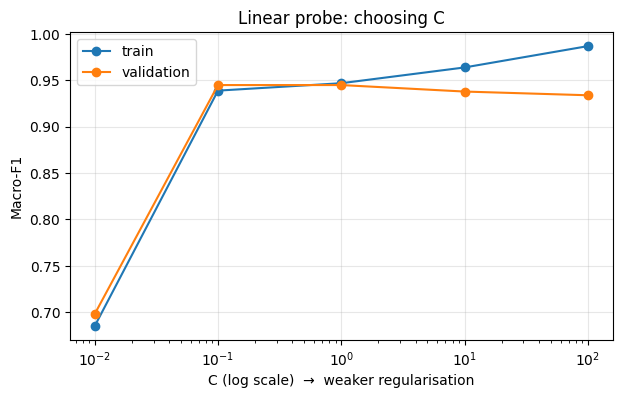

Best C = 0.1  (val macro-F1 0.945) → model saved


In [ ]:
# 4.3 Choose C on validation; save the best probe
import joblib

C_values = [0.01, 0.1, 1, 10, 100]
rows, models = [], {}

for C in C_values:
    m = LogisticRegression(C=C, max_iter=5000)
    m.fit(X_train, y_train)
    models[C] = m
    tr_pred, va_pred = m.predict(X_train), m.predict(X_val)
    rows.append({
        "C": C,
        "train_macro_f1": round(f1_score(y_train, tr_pred, average="macro"), 3),
        "val_accuracy":   round(accuracy_score(y_val, va_pred), 3),
        "val_macro_f1":   round(f1_score(y_val, va_pred, average="macro"), 3),
    })

c_results = pd.DataFrame(rows)
display(c_results)

# Plot: train vs validation macro-F1 for each C
plt.figure(figsize=(7, 4))
plt.plot(c_results["C"], c_results["train_macro_f1"], "o-", label="train")
plt.plot(c_results["C"], c_results["val_macro_f1"], "o-", label="validation")
plt.xscale("log")
plt.xlabel("C (log scale)  →  weaker regularisation")
plt.ylabel("Macro-F1")
plt.title("Linear probe: choosing C")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(OUT_DIR / "linear_probe_C.png", dpi=200, bbox_inches="tight")
plt.show()

# Pick the best C on VALIDATION macro-F1 and save that model
best_row = c_results.loc[c_results["val_macro_f1"].idxmax()]
BEST_C = best_row["C"]
probe = models[BEST_C]
joblib.dump(probe, OUT_DIR / f"linear_probe_{MODEL_NAME}.joblib")
print(f"Best C = {BEST_C}  (val macro-F1 {best_row['val_macro_f1']}) → model saved")

experiments.append({
    "method": "linear probe",
    "model": f"{MODEL_NAME} / {PRETRAINED}",
    "template": f"LogReg C={BEST_C}",
    "val_accuracy": best_row["val_accuracy"],
    "val_macro_f1": best_row["val_macro_f1"],
})
pd.DataFrame(experiments).to_csv(OUT_DIR / "experiments.csv", index=False)

In [ ]:
# 4.4 Linear probe vs zero-shot, overall and per class
# Zero-shot predictions with the best template (from 3.6), on the same validation images
zs_pred = [CLASSES[i] for i in (val_emb @ text_emb.cpu().T).argmax(dim=1).numpy()]
lp_pred = probe.predict(X_val)

# Overall
comparison = pd.DataFrame([
    {"method": "zero-shot CLIP",    "val_accuracy": accuracy_score(y_val, zs_pred), "val_macro_f1": f1_score(y_val, zs_pred, average="macro"), "errors": int((np.array(zs_pred) != y_val).sum())},
    {"method": f"linear probe C={BEST_C}", "val_accuracy": accuracy_score(y_val, lp_pred), "val_macro_f1": f1_score(y_val, lp_pred, average="macro"), "errors": int((lp_pred != y_val).sum())},
]).round(3)
display(comparison)

# Per class: where did training data help most?
per_class = pd.DataFrame({
    "zero-shot F1":    f1_score(y_val, zs_pred, labels=CLASSES, average=None),
    "linear probe F1": f1_score(y_val, lp_pred, labels=CLASSES, average=None),
}, index=CLASSES).round(3)
per_class["gain"] = (per_class["linear probe F1"] - per_class["zero-shot F1"]).round(3)
display(per_class.sort_values("gain", ascending=False))

,method,val_accuracy,val_macro_f1,errors
0,zero-shot CLIP,0.938,0.939,49
1,linear probe C=0.1,0.944,0.945,44


,zero-shot F1,linear probe F1,gain
Kitchen,0.893,0.904,0.011
Livingroom,0.939,0.945,0.006
Dinning,0.899,0.905,0.006
Bathroom,0.973,0.978,0.005
Bedroom,0.989,0.992,0.003


**Findings**
- **C = 0.1** gives the best validation macro-F1 (0.945; C = 1 ties). Very small C (0.01) underfits badly (0.698): the embeddings are normalised to length 1, so the classifier needs fairly large weights to separate the classes. Large C (10, 100) overfits: train F1 rises to 0.987 while validation drops.
- Labelled data adds only a little on top of zero-shot: validation errors fall from 49 to 44, every class gains, most of all **kitchen** (+0.011 F1).

---
## 5. Model C: fine-tuning ResNet-18

The classic approach: start from a CNN pretrained on ImageNet (1.2M photos), replace the last layer with a 5-class layer, and train the whole network on the room photos.

**Augmentation follows one rule: only changes real listing photos actually show.** Horizontal flips, moderate crops (scale 0.6–1.0), small tilts (±8°) with reflect padding instead of black corners, mild perspective, brightness/contrast jitter, warm/cool white balance, slight blur, sensor noise, JPEG re-compression and cutout. **No** vertical flips, large rotations, hue shifts or elastic distortion: floors are never at the top of a photo, and straight walls are a strong cue. Validation and test images are only resized and normalised.

In [ ]:
# 5.1 Realistic augmentation for training, plain resize for evaluation
import torch
from torchvision.transforms import v2

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
IMG_SIZE = 224

class ColorTemperature:
    """Warm/cool white-balance shift (yellow bulbs vs cool LEDs): scale red up and blue down, or the reverse."""
    def __init__(self, max_shift=0.08, p=0.5):
        self.max_shift, self.p = max_shift, p
    def __call__(self, img):  # float tensor, 3 × H × W, values 0–1
        if torch.rand(1).item() > self.p:
            return img
        t = (torch.rand(1).item() * 2 - 1) * self.max_shift  # negative = cooler, positive = warmer
        scale = torch.tensor([1 + t, 1.0, 1 - t]).view(3, 1, 1)
        return (img * scale).clamp(0, 1)

class AddGaussianNoise:
    """Mild sensor noise, like a cheap phone camera in low light."""
    def __init__(self, std=0.02, p=0.2):
        self.std, self.p = std, p
    def __call__(self, img):
        if torch.rand(1).item() > self.p:
            return img
        return (img + torch.randn_like(img) * self.std).clamp(0, 1)

# JPEG re-compression needs torchvision 0.20+; skip it if this Colab has an older version
jpeg = [v2.RandomApply([v2.JPEG(quality=(40, 95))], p=0.3)] if hasattr(v2, "JPEG") else []
print("JPEG augmentation:", "on" if jpeg else "not available in this torchvision version")

train_transform = v2.Compose([
    v2.ToImage(),                                                   # PIL image → uint8 tensor
    # Framing: moderate zoom/crop, keeps the bed / stove / sofa in view
    v2.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(3/4, 4/3), antialias=True),
    v2.RandomHorizontalFlip(p=0.5),                                 # a mirrored room is still that room
    # Tilt and camera angle, with reflect padding so no black corners appear
    v2.Pad(40, padding_mode="reflect"),
    v2.RandomApply([v2.RandomRotation(degrees=8)], p=0.4),          # ±8°: a slightly tilted phone
    v2.RandomPerspective(distortion_scale=0.12, p=0.3),             # mild change of camera height/angle
    v2.CenterCrop(IMG_SIZE),                                        # cut away the padding again
    # Lighting: brightness, contrast, mild saturation, no hue shift
    v2.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.15, hue=0.0),
    *jpeg,                                                          # heavy listing-site compression
    v2.ToDtype(torch.float32, scale=True),                          # uint8 0–255 → float 0–1
    ColorTemperature(max_shift=0.08, p=0.5),
    v2.RandomApply([v2.GaussianBlur(kernel_size=5, sigma=(0.1, 1.2))], p=0.2),  # slight motion/focus blur
    AddGaussianNoise(std=0.02, p=0.2),
    v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    v2.RandomErasing(p=0.25, scale=(0.02, 0.12), value=0),          # cutout: a person or furniture blocking part of the view
])

eval_transform = v2.Compose([                                       # validation and test: NO augmentation
    v2.ToImage(),
    v2.Resize((IMG_SIZE, IMG_SIZE), antialias=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

JPEG augmentation: on


In [ ]:
# 5.2 Datasets and loaders
from torch.utils.data import Dataset, DataLoader

CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}  # same class order as Steps 3–4

class RoomDataset(Dataset):
    def __init__(self, table, transform):
        self.paths = table["path"].tolist()
        self.labels = [CLASS_TO_IDX[l] for l in table["label"]]
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i]

train_ds = RoomDataset(train_df, train_transform)
val_ds   = RoomDataset(val_df, eval_transform)

BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

images, labels = next(iter(train_loader))
print(f"Train: {len(train_ds)} images, {len(train_loader)} batches | Val: {len(val_ds)} images, {len(val_loader)} batches")
print("One batch:", tuple(images.shape), "labels:", tuple(labels.shape))

Train: 3674 images, 58 batches | Val: 788 images, 13 batches
One batch: (64, 3, 224, 224) labels: (64,)


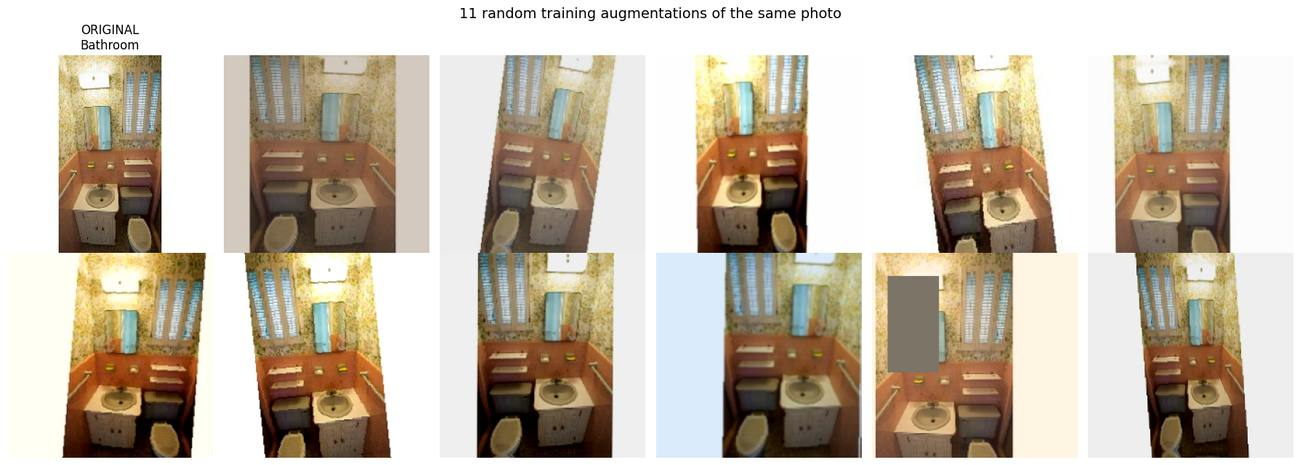

In [ ]:
# 5.3 Look at the augmentations: every version should still be a believable photo
def denormalize(t):
    """Undo the ImageNet normalisation so the tensor can be shown as a picture."""
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

idx = 0  # change to look at other images
original = Image.open(train_df.loc[idx, "path"]).convert("RGB")

fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
axes[0, 0].imshow(original)
axes[0, 0].set_title(f"ORIGINAL\n{train_df.loc[idx, 'label']}")
for ax in axes.flat[1:]:
    ax.imshow(denormalize(train_transform(original)))
for ax in axes.flat:
    ax.axis("off")
plt.suptitle("11 random training augmentations of the same photo", fontsize=14)
plt.tight_layout()
plt.savefig(OUT_DIR / "augmentation_examples.png", dpi=150, bbox_inches="tight")
plt.show()

**Leakage check.** The dataset has no listing IDs, so photos of the same room could land in different splits. Comparing the CLIP embedding of every validation image with every training image finds near-copies.

Validation images with a near-duplicate in train (cosine > 0.95): 41 of 788


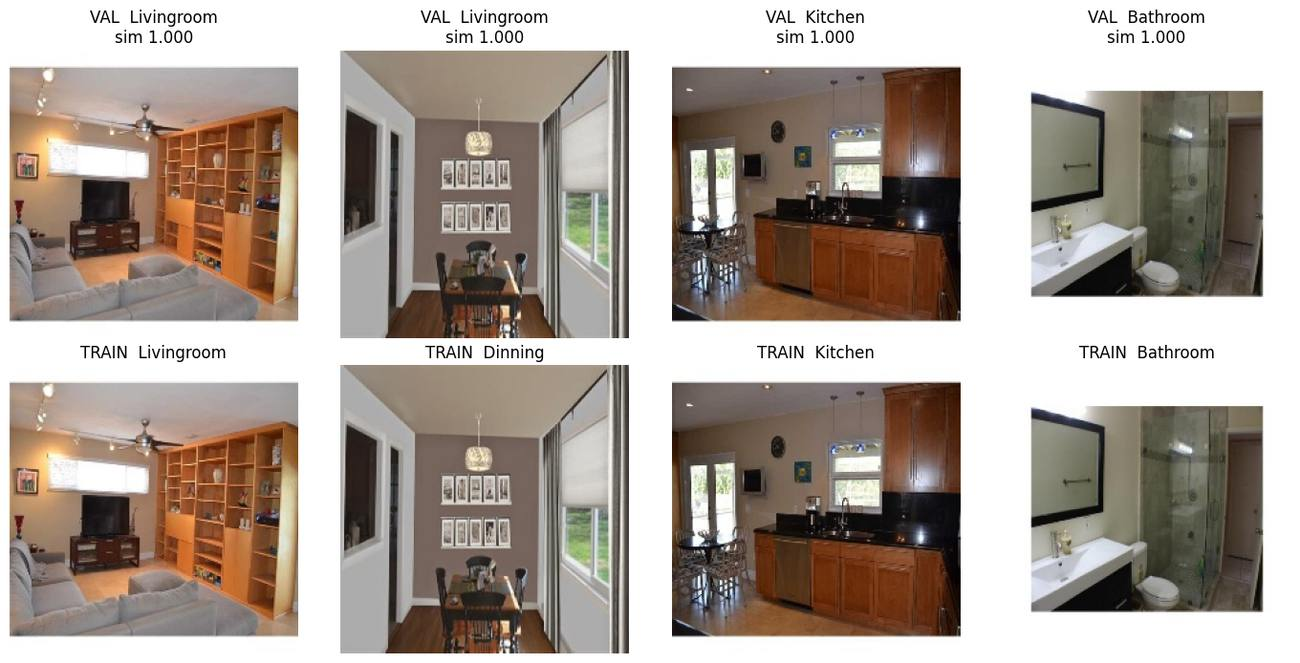

In [ ]:
# 5.4 Leakage check: validation images that are near-copies of a training image
sim = val_emb @ train_emb.T                 # cosine similarity, every val image vs every train image
best_sim, best_idx = sim.max(dim=1)
THRESH = 0.95
n_dupes = int((best_sim > THRESH).sum())
print(f"Validation images with a near-duplicate in train (cosine > {THRESH}): {n_dupes} of {len(val_emb)}")

# Show the 4 closest pairs
top = best_sim.argsort(descending=True)[:4]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for col, v in enumerate(top.tolist()):
    t = best_idx[v].item()
    axes[0, col].imshow(Image.open(val_df.loc[v, "path"]).convert("RGB"))
    axes[0, col].set_title(f"VAL  {val_df.loc[v, 'label']}\nsim {best_sim[v]:.3f}")
    axes[1, col].imshow(Image.open(train_df.loc[t, "path"]).convert("RGB"))
    axes[1, col].set_title(f"TRAIN  {train_df.loc[t, 'label']}")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# 5.5 Does the overlap inflate the score?
dupe_mask = (best_sim > 0.95).numpy()   # True for the 41 validation images with a copy in train
clean = ~dupe_mask

lp_pred = probe.predict(val_emb.numpy())
y = val_df["label"].to_numpy()

print(f"Linear probe, all val images  ({len(y)}): macro-F1 {f1_score(y, lp_pred, average='macro'):.3f}")
print(f"Linear probe, without dupes   ({clean.sum()}): macro-F1 {f1_score(y[clean], lp_pred[clean], average='macro'):.3f}")
print(f"Accuracy on the 41 duplicates only: {(lp_pred[dupe_mask] == y[dupe_mask]).mean():.3f}")

Linear probe, all val images  (788): macro-F1 0.945
Linear probe, without dupes   (747): macro-F1 0.949
Accuracy on the 41 duplicates only: 0.878


**41 of 788 validation images (5.2%) have a near-copy in the training set**, and the closest pairs are the same photo (similarity 1.000). This did **not** inflate the results: without the duplicates, the linear probe's macro-F1 goes slightly *up* (0.945 → 0.949), and the probe is *less* accurate on the duplicates (87.8%) than on the rest. The reason is label noise: some photos appear twice with **different labels**, for example the same dining-room photo labelled *Dinning* in train and *Livingroom* in validation. That caps accuracy for the living/dining pair.

In [ ]:
!pip -q install timm

In [ ]:
# 5.6 ResNet-18 pretrained on ImageNet, new 5-class head
import timm

ARCH = "resnet18"  # or "efficientnet_b0"; try both later if you have time

# Pretrained on ImageNet, with a NEW last layer for our 5 room classes
cnn = timm.create_model(ARCH, pretrained=True, num_classes=len(CLASSES))
cnn = cnn.to(device)

# 1. Size
n_params = sum(p.numel() for p in cnn.parameters())
print(f"{ARCH}: {n_params / 1e6:.1f} million parameters")

# 2. The new classification layer (randomly initialised; everything before it is pretrained)
print("New last layer:", cnn.get_classifier())

# 3. Check the normalisation the pretrained weights expect matches what we used in 5.1
cfg = timm.data.resolve_model_data_config(cnn)
print("Expected input size:", cfg["input_size"], "| mean:", cfg["mean"], "| std:", cfg["std"])
assert tuple(round(x, 3) for x in cfg["mean"]) == tuple(round(x, 3) for x in IMAGENET_MEAN), "Mean doesn't match 5.1"

# 4. Test one batch: 64 images in → 64 rows of 5 scores out
images, labels = next(iter(train_loader))
cnn.eval()
with torch.no_grad():
    logits = cnn(images.to(device))
print("Batch in:", tuple(images.shape), "→ out:", tuple(logits.shape))
print("Untrained predictions (should be near random, ~20%):",
      f"{(logits.argmax(1).cpu() == labels).float().mean():.0%}")

resnet18: 11.2 million parameters
New last layer: Linear(in_features=512, out_features=5, bias=True)
Expected input size: (3, 224, 224) | mean: (0.485, 0.456, 0.406) | std: (0.229, 0.224, 0.225)
Batch in: (64, 3, 224, 224) → out: (64, 5)
Untrained predictions (should be near random, ~20%): 38%


In [ ]:
# 5.7 Training loop: two learning rates, warm-up + decay, mixed precision, checkpoint every epoch
import time
import torch.nn as nn
import torch.nn.functional as F
from torch.amp import autocast, GradScaler

# ---------------- settings ----------------
SEED = 42
EPOCHS = 12
LR_BACKBONE = 2e-4        # pretrained layers: small steps, so we don't destroy what they learned
LR_HEAD = 1e-3            # new last layer: bigger steps, it starts from random
WEIGHT_DECAY = 0.05
LABEL_SMOOTHING = 0.1     # softens targets a little; helps with the noisy living/dining labels
MIX_PROB = 0.0            # MixUp/CutMix off: the first run used 0.3 and learned more slowly
FRESH_START = True        # True = ignore any saved checkpoint and train from scratch

torch.manual_seed(SEED)
np.random.seed(SEED)
use_amp = device == "cuda"

CKPT_DIR = OUT_DIR / "checkpoints"
CKPT_DIR.mkdir(exist_ok=True)
LAST_CKPT = CKPT_DIR / f"{ARCH}_last.pt"     # full state after the latest epoch (for resuming)
BEST_WEIGHTS = OUT_DIR / f"{ARCH}_best.pt"   # weights of the best epoch (for Step 6 and the demo)

# ---------------- model, optimiser, schedule ----------------
cnn = timm.create_model(ARCH, pretrained=True, num_classes=len(CLASSES)).to(device)

head_params = list(cnn.get_classifier().parameters())
head_ids = {id(p) for p in head_params}
backbone_params = [p for p in cnn.parameters() if id(p) not in head_ids]

optimizer = torch.optim.AdamW(
    [{"params": backbone_params, "lr": LR_BACKBONE},
     {"params": head_params, "lr": LR_HEAD}],
    weight_decay=WEIGHT_DECAY,
)
# Warm up for the first 15% of steps, then smoothly lower the learning rate to near zero
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=[LR_BACKBONE, LR_HEAD],
    total_steps=EPOCHS * len(train_loader), pct_start=0.15,
)
scaler = GradScaler("cuda", enabled=use_amp)
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
mixer = v2.RandomChoice([v2.MixUp(alpha=0.2, num_classes=len(CLASSES)),
                         v2.CutMix(alpha=1.0, num_classes=len(CLASSES))])

# ---------------- resume if a checkpoint exists ----------------
start_epoch, history, best_f1 = 0, [], -1.0
if LAST_CKPT.exists() and not FRESH_START:
    ck = torch.load(LAST_CKPT, map_location=device, weights_only=False)
    cnn.load_state_dict(ck["model"])
    optimizer.load_state_dict(ck["optimizer"])
    scheduler.load_state_dict(ck["scheduler"])
    scaler.load_state_dict(ck["scaler"])
    start_epoch, history, best_f1 = ck["epoch"] + 1, ck["history"], ck["best_f1"]
    print(f"Resuming from epoch {start_epoch + 1} (best val macro-F1 so far: {best_f1:.3f})")

# ---------------- evaluation ----------------
def evaluate(model, loader):
    """Average loss (plain cross-entropy), accuracy and macro-F1 on a loader."""
    model.eval()
    total_loss, preds, trues = 0.0, [], []
    with torch.no_grad(), autocast("cuda", enabled=use_amp):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += F.cross_entropy(out.float(), y, reduction="sum").item()
            preds.append(out.argmax(1).cpu())
            trues.append(y.cpu())
    preds, trues = torch.cat(preds).numpy(), torch.cat(trues).numpy()
    return (total_loss / len(loader.dataset),
            accuracy_score(trues, preds),
            f1_score(trues, preds, average="macro"))

# ---------------- training ----------------
for epoch in range(start_epoch, EPOCHS):
    cnn.train()
    t0, running_loss, seen = time.time(), 0.0, 0

    for x, y in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}", leave=False):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        if torch.rand(1).item() < MIX_PROB:
            x, y = mixer(x, y)                      # y becomes soft labels, e.g. 70% kitchen + 30% dining

        optimizer.zero_grad(set_to_none=True)
        with autocast("cuda", enabled=use_amp):     # mixed precision: faster on the T4
            loss = criterion(cnn(x), y)
        scaler.scale(loss).backward()               # compute gradients
        scaler.step(optimizer)                      # update the weights
        scaler.update()
        scheduler.step()                            # adjust the learning rate

        running_loss += loss.item() * x.size(0)
        seen += x.size(0)

    train_loss = running_loss / seen
    val_loss, val_acc, val_f1 = evaluate(cnn, val_loader)
    history.append({"epoch": epoch + 1, "train_loss": train_loss, "val_loss": val_loss,
                    "val_accuracy": val_acc, "val_macro_f1": val_f1,
                    "seconds": round(time.time() - t0)})

    improved = val_f1 > best_f1
    if improved:
        best_f1 = val_f1
        torch.save(cnn.state_dict(), BEST_WEIGHTS)

    torch.save({"model": cnn.state_dict(), "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                "epoch": epoch, "history": history, "best_f1": best_f1}, LAST_CKPT)

    print(f"Epoch {epoch + 1}/{EPOCHS} | train loss {train_loss:.3f} | val loss {val_loss:.3f} | "
          f"val acc {val_acc:.3f} | val macro-F1 {val_f1:.3f} | {history[-1]['seconds']}s"
          + ("  ★ best, saved" if improved else ""))

print(f"\nDone. Best val macro-F1: {best_f1:.3f}")

Epoch 1/12 | train loss 1.581 | val loss 1.488 | val acc 0.449 | val macro-F1 0.362 | 48s  ★ best, saved
Epoch 2/12 | train loss 1.314 | val loss 0.825 | val acc 0.734 | val macro-F1 0.731 | 39s  ★ best, saved
Epoch 3/12 | train loss 0.912 | val loss 0.543 | val acc 0.822 | val macro-F1 0.824 | 39s  ★ best, saved
Epoch 4/12 | train loss 0.778 | val loss 0.471 | val acc 0.845 | val macro-F1 0.847 | 43s  ★ best, saved
Epoch 5/12 | train loss 0.730 | val loss 0.437 | val acc 0.860 | val macro-F1 0.862 | 41s  ★ best, saved
Epoch 6/12 | train loss 0.696 | val loss 0.434 | val acc 0.859 | val macro-F1 0.862 | 43s
Epoch 7/12 | train loss 0.680 | val loss 0.423 | val acc 0.865 | val macro-F1 0.868 | 41s  ★ best, saved
Epoch 8/12 | train loss 0.651 | val loss 0.408 | val acc 0.876 | val macro-F1 0.877 | 41s  ★ best, saved
Epoch 9/12 | train loss 0.633 | val loss 0.401 | val acc 0.879 | val macro-F1 0.882 | 44s  ★ best, saved
Epoch 10/12 | train loss 0.634 | val loss 0.403 | val acc 0.874 | val 

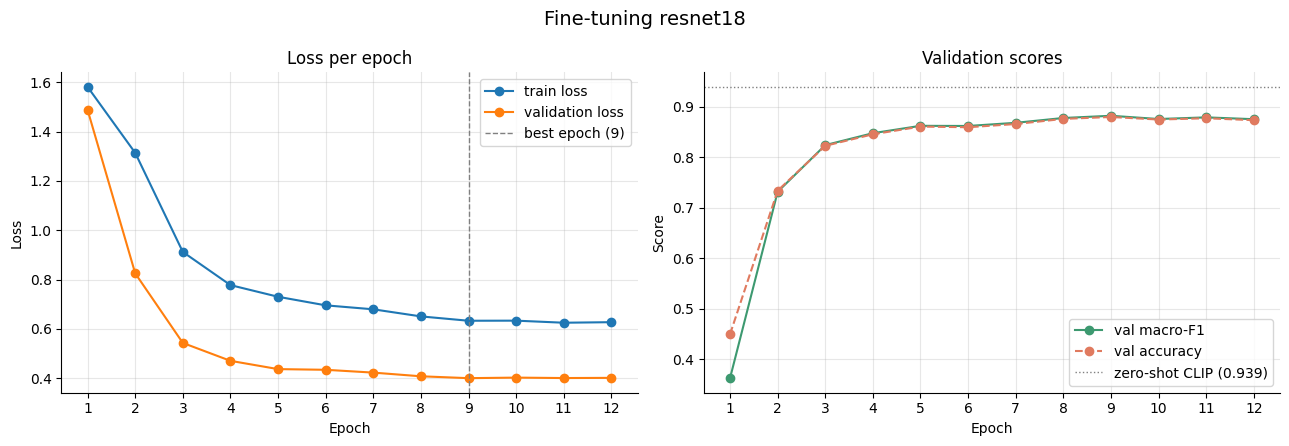

Best weights (epoch 9) reloaded: val accuracy 0.879, val macro-F1 0.882
Saved: resnet18_best.pt | resnet18_history.csv | resnet18_training_curves.png


,method,model,template,val_accuracy,val_macro_f1,params_M,images_per_sec
0,zero-shot,ViT-B-32 / laion2b_s34b_b79k,a photo of a {}.,0.938,0.939,NaN,NaN
1,zero-shot,ViT-B-32 / laion2b_s34b_b79k,a real estate photo of a {}.,0.934,0.934,NaN,NaN
2,zero-shot,ViT-B-32 / laion2b_s34b_b79k,an interior photo of a {} in a home.,0.935,0.935,NaN,NaN
3,zero-shot,ViT-B-32 / laion2b_s34b_b79k,a professional listing photo of a {}.,0.934,0.933,NaN,NaN
4,zero-shot,ViT-B-32 / laion2b_s34b_b79k,"a photo of a {}, a room in a house.",0.938,0.938,NaN,NaN
5,zero-shot,ViT-B-32 / laion2b_s34b_b79k,ENSEMBLE (all templates),0.937,0.936,NaN,NaN
6,zero-shot,ViT-B-16-SigLIP / webli,a photo of a {}.,0.944,0.945,203.0,60.0
7,zero-shot,ViT-L-14 / laion2b_s32b_b82k,a photo of a {}.,0.945,0.946,428.0,17.0
8,linear probe,ViT-B-32 / laion2b_s34b_b79k,LogReg C=0.1,0.944,0.945,NaN,NaN
9,fine-tune,resnet18 / ImageNet,"5 epochs, best epoch 4",0.822,0.825,NaN,NaN


In [ ]:
# 5.8 Training curves; reload the best epoch's weights
hist = pd.DataFrame(history)
hist.to_csv(OUT_DIR / f"{ARCH}_history.csv", index=False)
best_epoch = int(hist.loc[hist["val_macro_f1"].idxmax(), "epoch"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(hist["epoch"], hist["train_loss"], "o-", label="train loss")
ax1.plot(hist["epoch"], hist["val_loss"], "o-", label="validation loss")
ax1.axvline(best_epoch, color="grey", linestyle="--", linewidth=1, label=f"best epoch ({best_epoch})")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.set_title("Loss per epoch"); ax1.legend()

ax2.plot(hist["epoch"], hist["val_macro_f1"], "o-", color="#3D9970", label="val macro-F1")
ax2.plot(hist["epoch"], hist["val_accuracy"], "o--", color="#E07A5F", label="val accuracy")
ax2.axhline(0.939, color="grey", linestyle=":", linewidth=1, label="zero-shot CLIP (0.939)")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Score"); ax2.set_title("Validation scores"); ax2.legend()

for ax in (ax1, ax2):
    ax.set_xticks(hist["epoch"]); ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
plt.suptitle(f"Fine-tuning {ARCH}", fontsize=14)
plt.tight_layout()
plt.savefig(OUT_DIR / f"{ARCH}_training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

# Reload the BEST weights (not the last epoch) and confirm the score
cnn.load_state_dict(torch.load(BEST_WEIGHTS, map_location=device))
_, best_acc, best_val_f1 = evaluate(cnn, val_loader)
print(f"Best weights (epoch {best_epoch}) reloaded: val accuracy {best_acc:.3f}, val macro-F1 {best_val_f1:.3f}")
print("Saved:", BEST_WEIGHTS.name, "|", f"{ARCH}_history.csv", "|", f"{ARCH}_training_curves.png")

experiments.append({"method": "fine-tune", "model": f"{ARCH} / ImageNet", "template": f"{EPOCHS} epochs, best epoch {best_epoch}",
                    "val_accuracy": round(best_acc, 3), "val_macro_f1": round(best_val_f1, 3)})
pd.DataFrame(experiments).to_csv(OUT_DIR / "experiments.csv", index=False)
display(pd.DataFrame(experiments))

**Fine-tuning results.** A first run (5 epochs, MixUp/CutMix on 30% of batches) reached 0.825 validation macro-F1 with its best epoch at 4 of 5, so it was still learning. The run above trains for 12 epochs without MixUp/CutMix and reaches **0.882** (best epoch 9, validation loss flat afterwards), so it has converged. Train loss stays above validation loss because training images are augmented and scored with label smoothing.

It still sits about 6 points below zero-shot CLIP (0.939) and the linear probe (0.945). On ~3,700 training images, what a model learned in pretraining matters more than the training added on top: CLIP's captioned web images include many homes, while ImageNet is mostly single objects. **Chosen model: linear probe on CLIP ViT-B-32**, as accurate as any option within noise, trained in seconds, cheap to run.

---
## 6. Test-set evaluation and error analysis

Each model is scored **once** on the 788 untouched test images. From here on, the model is the one chosen on validation (section 5), not the test-set leader.

In [ ]:
# 6.1 Score every model once on the test set
import time, gc
from sklearn.linear_model import LogisticRegression

y_test = test_df["label"].to_numpy()
test_preds = {}   # keeps every model's predictions for 6.2–6.4
rows = []

def add_result(name, method, preds, train_time, notes):
    test_preds[name] = np.array(preds)
    rows.append({
        "model": name,
        "method": method,
        "test_accuracy": round(accuracy_score(y_test, preds), 3),
        "test_macro_f1": round(f1_score(y_test, preds, average="macro"), 3),
        "training_time": train_time,
        "notes": notes,
    })

# ---------- 1. Zero-shot CLIP ViT-B-32 (best template from 3.6) ----------
zs = [CLASSES[i] for i in (test_emb @ text_emb.cpu().T).argmax(dim=1).numpy()]
add_result("CLIP ViT-B-32", "zero-shot", zs, "none",
           f"template '{BEST_TEMPLATE}', 151M params, no training data")

# ---------- 2. Linear probe on CLIP ViT-B-32 embeddings ----------
t0 = time.time()
LogisticRegression(C=BEST_C, max_iter=5000).fit(train_emb.numpy(), train_df["label"])  # re-fit only to time it
probe_time = time.time() - t0
lp = probe.predict(test_emb.numpy())   # predictions from the saved probe (Step 4)
add_result("CLIP ViT-B-32 + LogReg", "linear probe", lp, f"{probe_time:.1f} s (+ ~1 min to embed images)",
           f"C={BEST_C}, CLIP frozen")

# ---------- 3. Fine-tuned ResNet-18 (best epoch weights) ----------
cnn = timm.create_model(ARCH, pretrained=False, num_classes=len(CLASSES)).to(device)
cnn.load_state_dict(torch.load(BEST_WEIGHTS, map_location=device))
cnn.eval()

test_loader = DataLoader(RoomDataset(test_df, eval_transform), batch_size=64, shuffle=False, num_workers=2)
cnn_preds = []
with torch.no_grad(), autocast("cuda", enabled=use_amp):
    for x, _ in test_loader:
        cnn_preds.append(cnn(x.to(device)).argmax(1).cpu())
ft = [CLASSES[i] for i in torch.cat(cnn_preds).numpy()]

hist = pd.read_csv(OUT_DIR / f"{ARCH}_history.csv")
best_ep = int(hist.loc[hist["val_macro_f1"].idxmax(), "epoch"])
add_result(f"{ARCH} (ImageNet)", "fine-tune", ft, f"{hist['seconds'].sum() / 60:.1f} min ({len(hist)} epochs)",
           f"best epoch {best_ep}, 11M params, augmentation + label smoothing")

# ---------- 4. Bigger zero-shot models from 3.7 ----------
def zero_shot_on_test(model_name, pretrained, batch_size=64):
    m, _, prep = open_clip.create_model_and_transforms(model_name, pretrained=pretrained)
    tok = open_clip.get_tokenizer(model_name)
    m = m.to(device).eval()
    with torch.no_grad():
        t = m.encode_text(tok([BEST_TEMPLATE.format(CLASS_NAMES[c]) for c in CLASSES]).to(device))
        t = t / t.norm(dim=-1, keepdim=True)
        loader = DataLoader(ImageDatasetWith(test_df["path"], prep), batch_size=batch_size, num_workers=2)
        embs = []
        for images in tqdm(loader, desc=model_name):
            e = m.encode_image(images.to(device))
            embs.append((e / e.norm(dim=-1, keepdim=True)).cpu())
        preds = [CLASSES[i] for i in (torch.cat(embs) @ t.cpu().T).argmax(dim=1).numpy()]
    del m, t
    gc.collect(); torch.cuda.empty_cache()
    return preds

add_result("SigLIP ViT-B-16", "zero-shot", zero_shot_on_test("ViT-B-16-SigLIP", "webli"), "none", "203M params")
add_result("CLIP ViT-L-14", "zero-shot", zero_shot_on_test("ViT-L-14", "laion2b_s32b_b82k"), "none", "428M params, slowest")

# ---------- results table ----------
results = pd.DataFrame(rows).sort_values("test_macro_f1", ascending=False).reset_index(drop=True)
results.to_csv(OUT_DIR / "results_test.csv", index=False)
display(results)

,model,method,test_accuracy,test_macro_f1,training_time,notes
0,SigLIP ViT-B-16,zero-shot,0.952,0.954,none,203M params
1,CLIP ViT-L-14,zero-shot,0.949,0.951,none,"428M params, slowest"
2,CLIP ViT-B-32,zero-shot,0.947,0.950,none,"template 'a photo of a {}.', 151M params, no t..."
3,CLIP ViT-B-32 + LogReg,linear probe,0.944,0.946,1.9 s (+ ~1 min to embed images),"C=0.1, CLIP frozen"
4,resnet18 (ImageNet),fine-tune,0.891,0.893,8.3 min (12 epochs),"best epoch 9, 11M params, augmentation + label..."


Final model (chosen on validation): CLIP ViT-B-32 + LogReg

              precision    recall  f1-score   support

    bathroom      0.978     0.989     0.984        91
     bedroom      0.984     0.979     0.981       187
 dining room      0.939     0.891     0.914       174
     kitchen      0.905     0.924     0.915       145
 living room      0.924     0.953     0.938       191

    accuracy                          0.944       788
   macro avg      0.946     0.947     0.946       788
weighted avg      0.944     0.944     0.944       788


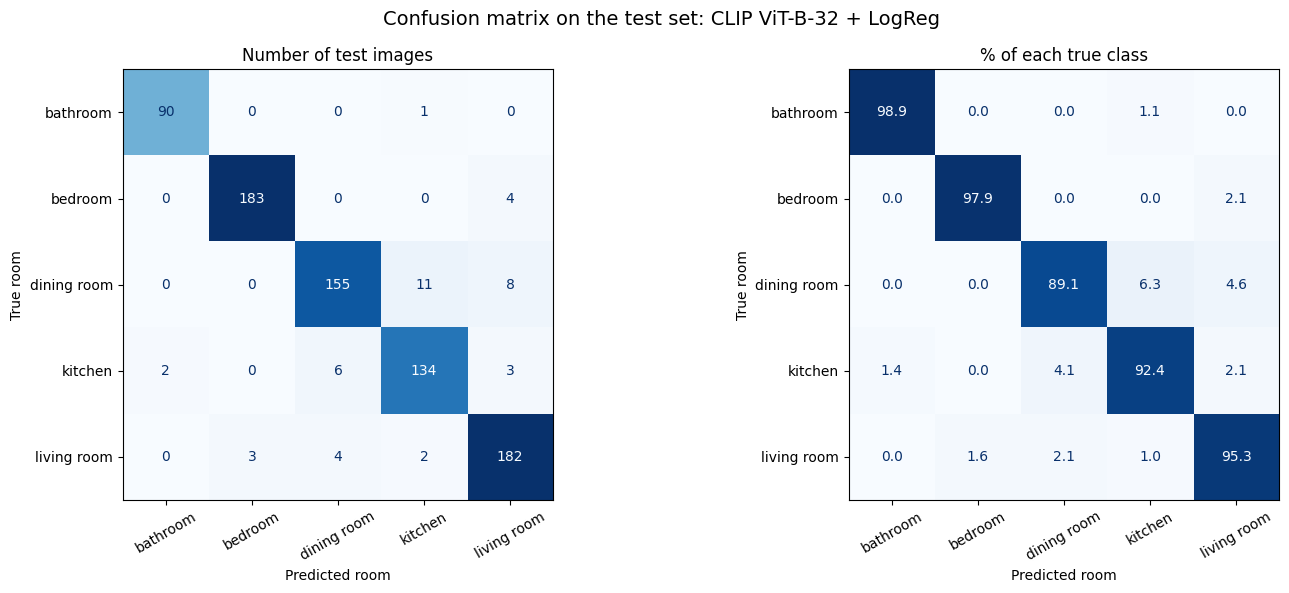

Total mistakes: 44 of 788


,true room,predicted as,images
2,dining room,kitchen,11
3,dining room,living room,8
5,kitchen,dining room,6
1,bedroom,living room,4
8,living room,dining room,4
7,living room,bedroom,3


In [ ]:
# 6.2 Classification report and confusion matrix for the chosen model
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# The model chosen on VALIDATION in Step 4 (not the test-set leader)
BEST_MODEL = "CLIP ViT-B-32 + LogReg"
best_pred = test_preds[BEST_MODEL]
nice = [CLASS_NAMES[c] for c in CLASSES]  # "dining room" instead of "Dinning", etc.
print(f"Final model (chosen on validation): {BEST_MODEL}\n")

# ---------- 6.2 Classification report ----------
print(classification_report(y_test, best_pred, labels=CLASSES, target_names=nice, digits=3))

report = pd.DataFrame(classification_report(y_test, best_pred, labels=CLASSES, target_names=nice,
                                            output_dict=True)).T.round(3)
report.to_csv(OUT_DIR / "classification_report_test.csv")

# ---------- 6.3 Confusion matrix: counts and row percentages ----------
cm = confusion_matrix(y_test, best_pred, labels=CLASSES)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100   # each row adds up to 100%

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ConfusionMatrixDisplay(cm, display_labels=nice).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title("Number of test images")

ConfusionMatrixDisplay(cm_pct, display_labels=nice).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".1f")
axes[1].set_title("% of each true class")

for ax in axes:
    ax.set_xlabel("Predicted room")
    ax.set_ylabel("True room")
    ax.tick_params(axis="x", rotation=30)
plt.suptitle(f"Confusion matrix on the test set: {BEST_MODEL}", fontsize=14)
plt.tight_layout()
plt.savefig(OUT_DIR / "confusion_matrix_test.png", dpi=200, bbox_inches="tight")
plt.show()

# ---------- Which pairs get mixed up most? ----------
pairs = [(nice[i], nice[j], cm[i, j]) for i in range(len(CLASSES)) for j in range(len(CLASSES)) if i != j and cm[i, j] > 0]
pairs = pd.DataFrame(pairs, columns=["true room", "predicted as", "images"]).sort_values("images", ascending=False)
print(f"Total mistakes: {cm.sum() - np.trace(cm)} of {cm.sum()}")
display(pairs.head(6))

**Findings**
- **The top four models are tied.** SigLIP (0.954), ViT-L-14 (0.951), zero-shot ViT-B-32 (0.950) and the linear probe (0.946) are within 0.008, about 6 images. Their order even changed between validation and test (the probe led on validation, zero-shot leads on test), which is what noise looks like. Switching to the test-set leader now would make the reported number optimistic, so the validation choice stays.
- **Test scores match or beat validation** for every model, so choices made on validation hold up on unseen data.
- **Dining room is the hardest class** (recall 0.891). The most common confusions are dining → kitchen (11), dining → living room (8) and kitchen → dining (6): rooms that often share one open space.
- The fine-tuned ResNet-18 stays clearly behind (0.893).

44 mistakes out of 788 test images. Showing the 12 most confident:


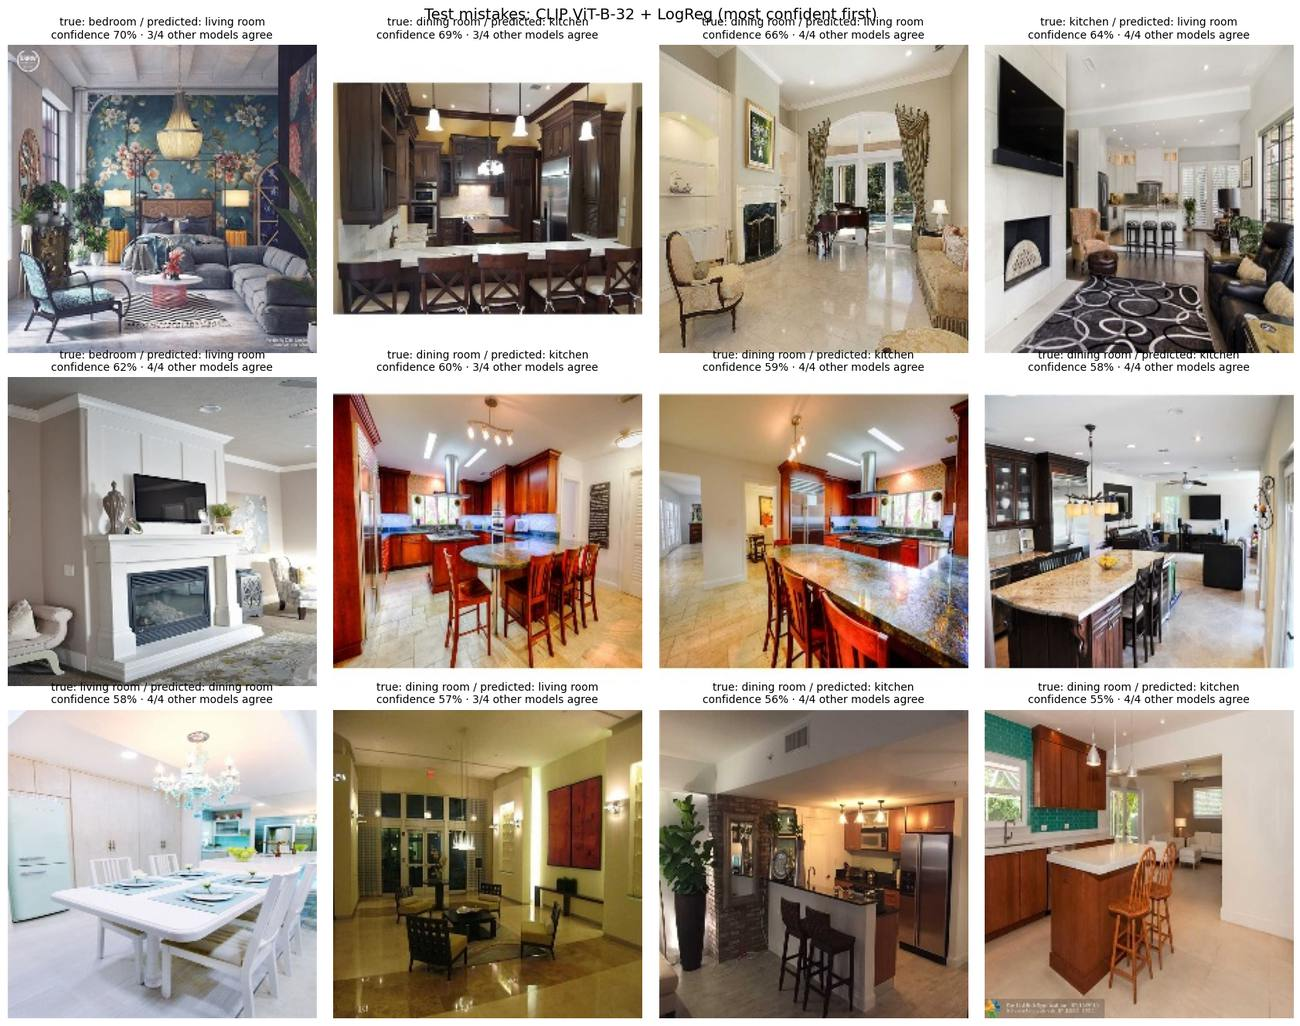

Mistakes where all 4 other models predicted the same wrong class: 13 of 44


In [ ]:
# 6.3 The 12 most confident mistakes, and how many other models agree
# Probability the probe gave to its (wrong) answer
proba = probe.predict_proba(test_emb.numpy())
pred_conf = proba.max(axis=1)

# How many of the OTHER models made the same wrong prediction?
other_models = [m for m in test_preds if m != BEST_MODEL]
wrong = np.where(best_pred != y_test)[0]
agree_counts = [sum(test_preds[m][i] == best_pred[i] for m in other_models) for i in wrong]

mistakes = pd.DataFrame({
    "idx": wrong,
    "true": y_test[wrong],
    "pred": best_pred[wrong],
    "confidence": pred_conf[wrong],
    "others_agree": agree_counts,      # out of len(other_models)
    "path": test_df["path"].to_numpy()[wrong],
}).sort_values("confidence", ascending=False).reset_index(drop=True)
mistakes.to_csv(OUT_DIR / "test_mistakes.csv", index=False)
print(f"{len(mistakes)} mistakes out of {len(y_test)} test images. Showing the 12 most confident:\n")

# Grid of the 12 most confident mistakes
fig, axes = plt.subplots(3, 4, figsize=(17, 13.5))
for ax, (_, r) in zip(axes.flat, mistakes.head(12).iterrows()):
    ax.imshow(Image.open(r["path"]).convert("RGB"))
    ax.set_title(f"true: {CLASS_NAMES[r['true']]} / predicted: {CLASS_NAMES[r['pred']]}\n"
                 f"confidence {r['confidence']:.0%} · {r['others_agree']}/{len(other_models)} other models agree",
                 fontsize=10)
    ax.axis("off")
for ax in axes.flat[len(mistakes):]:
    ax.axis("off")                     # hide empty panels if there are fewer than 12 mistakes
plt.suptitle(f"Test mistakes: {BEST_MODEL} (most confident first)", fontsize=14)
plt.tight_layout()
plt.savefig(OUT_DIR / "test_mistakes_grid.png", dpi=150, bbox_inches="tight")
plt.show()

# How many mistakes do ALL models agree on? (a strong sign the label itself may be wrong)
n_all = (mistakes["others_agree"] == len(other_models)).sum()
print(f"Mistakes where all {len(other_models)} other models predicted the same wrong class: {n_all} of {len(mistakes)}")

**What the mistakes show.** Most wrong predictions are photos that show **two rooms at once**: an open-plan living room with a dining table, or a kitchen that opens into a dining area. The label names one room but the photo contains two, so the model's answer is often as defensible as the label. In 13 of the 44 mistakes, **all four other models** predicted the same "wrong" class, a strong sign that the label itself is debatable.

**Possible fixes**
- **Two answers when unsure:** if the top two probabilities are close, return both ("living room / dining room"). The demo does this.
- **Multi-label classification:** a yes/no decision per room (sigmoid instead of softmax), so one photo can be living + dining. CLIP can do this zero-shot.
- **Detect objects first:** sofa, dining table, bed, oven, toilet (all COCO classes), then infer which rooms are present. Explainable.
- **Fix the labels:** re-label ambiguous and conflicting photos (model suggests, person confirms). Needed to train and measure any of the above fairly.

For a listing platform, multi-label also fits the product better: a search filter for "dining area" should find open-plan photos too.

---
## 7. Photo quality score

The classifier says *which room* a photo shows; the quality score says *whether the photo is usable*. It flags photos to send back to the broker, warns when a room prediction is unreliable, and feeds the cover picker.

Four classic, explainable measures, computed on a greyscale copy resized to a 224-px short side so one threshold works for small and large photos:

| Measure | How | Meaning |
|---|---|---|
| Sharpness | variance of the Laplacian (an edge filter) | low = blurry |
| Brightness | mean grey value (0–255) | too low = dark, too high = washed out |
| Contrast | standard deviation of grey values | low = flat |
| Resolution | shorter side in pixels | small = looks bad on large screens |

In [ ]:
# 7.1 Quality measures for one photo
import cv2
import numpy as np
from PIL import Image

ANALYSIS_SIZE = 224  # every photo is resized so its shorter side is 224 px before measuring

def photo_quality(path_or_image):
    """Return sharpness, brightness, contrast and short side for one photo.

    Accepts a file path or a PIL image (the Gradio demo will pass PIL images).
    """
    img = path_or_image if isinstance(path_or_image, Image.Image) else Image.open(path_or_image)
    img = img.convert("RGB")
    short_side = min(img.size)                     # original resolution, measured BEFORE resizing

    # Resize to a fixed scale so sharpness means the same thing for small and huge photos
    scale = ANALYSIS_SIZE / short_side
    img = img.resize((round(img.width * scale), round(img.height * scale)), Image.Resampling.LANCZOS)

    gray = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2GRAY)

    return {
        "sharpness":  float(cv2.Laplacian(gray, cv2.CV_64F).var()),  # high = sharp edges, low = blurry
        "brightness": float(gray.mean()),                            # 0 = black, 255 = white
        "contrast":   float(gray.std()),                             # low = flat and grey
        "short_side": int(short_side),                               # pixels of the shorter side
    }

# Try it on 3 test images
for p in test_df["path"].head(3):
    print(Path(p).name, photo_quality(p))

bed_185.jpg {'sharpness': 707.1003778291613, 'brightness': 130.6641222895408, 'contrast': 53.15214463567322, 'short_side': 224}
bed_23.jpg {'sharpness': 1467.0851493269042, 'brightness': 162.42229352678572, 'contrast': 57.71820651104797, 'short_side': 224}
living_1283.jpg {'sharpness': 3830.2831711135573, 'brightness': 86.74334343112245, 'contrast': 65.20905396188961, 'short_side': 224}


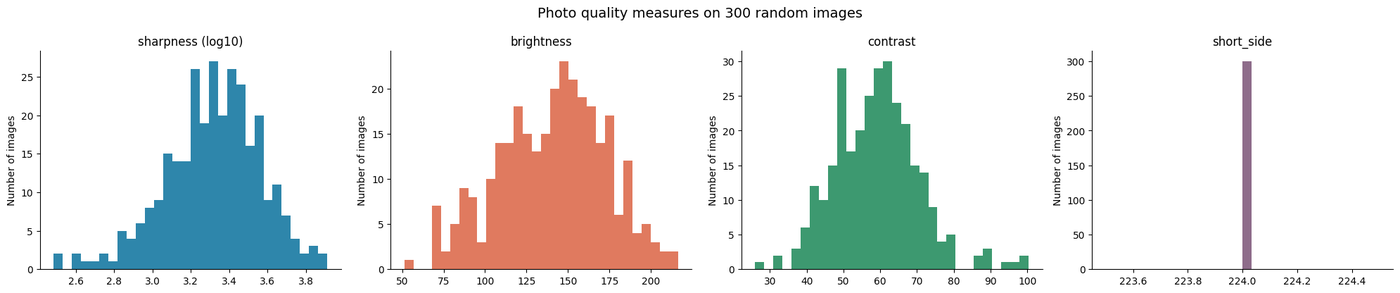

       sharpness  brightness  contrast  short_side
count      300.0       300.0     300.0       300.0
mean      2423.1       140.7      59.1       224.0
std       1344.3        32.2      11.5         0.0
min        305.3        51.4      26.0       224.0
5%         769.8        85.0      41.6       224.0
10%       1013.4        94.2      44.9       224.0
25%       1493.4       118.9      50.6       224.0
50%       2165.6       143.3      59.1       224.0
75%       3041.9       164.1      65.8       224.0
90%       4157.9       182.8      72.6       224.0
95%       4822.8       189.3      77.3       224.0
max       8176.2       216.4     100.4       224.0


In [ ]:
# 7.2 Measure 300 random photos
# ---------- Measure 300 random images ----------
sample = df.sample(n=300, random_state=SEED).reset_index(drop=True)
q = pd.DataFrame([photo_quality(p) for p in tqdm(sample["path"], desc="Measuring quality")])
q = pd.concat([sample[["path", "label"]], q], axis=1)
q.to_csv(OUT_DIR / "quality_sample_300.csv", index=False)

# ---------- Histograms ----------
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
specs = [("sharpness", "#2E86AB", True), ("brightness", "#E07A5F", False),
         ("contrast", "#3D9970", False), ("short_side", "#8E6C8A", False)]
for ax, (col, color, log) in zip(axes, specs):
    data = np.log10(q[col].clip(lower=1)) if log else q[col]
    ax.hist(data, bins=30, color=color)
    ax.set_title(f"{col} (log10)" if log else col)
    ax.set_ylabel("Number of images")
    ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Photo quality measures on 300 random images", fontsize=14)
plt.tight_layout()
plt.savefig(OUT_DIR / "quality_histograms.png", dpi=200, bbox_inches="tight")
plt.show()

# ---------- Summary numbers: percentiles help pick starting thresholds ----------
print(q[["sharpness", "brightness", "contrast", "short_side"]]
      .describe(percentiles=[0.05, 0.10, 0.25, 0.5, 0.75, 0.90, 0.95]).round(1))

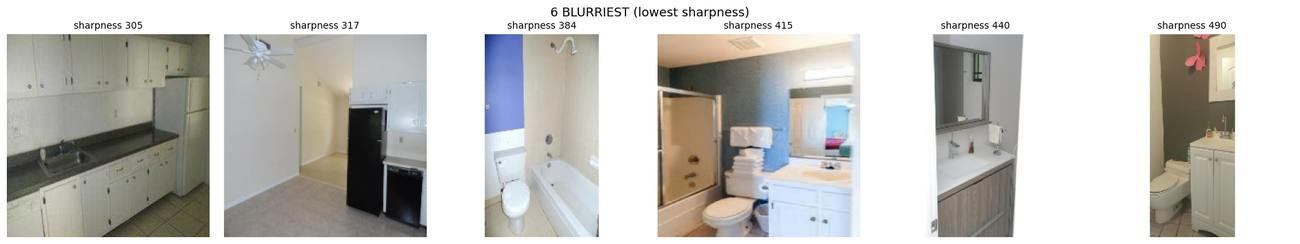

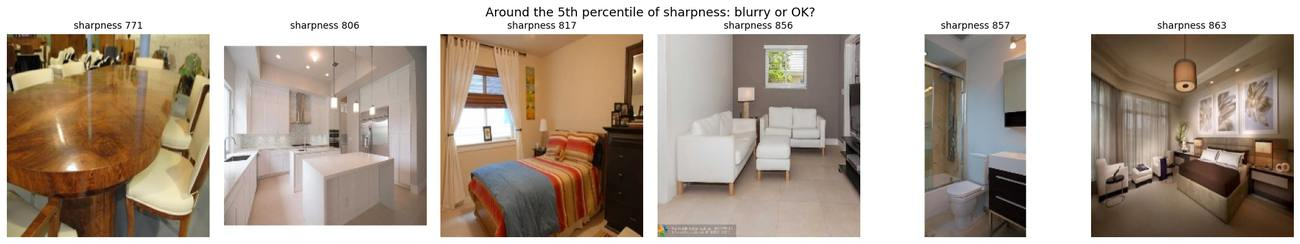

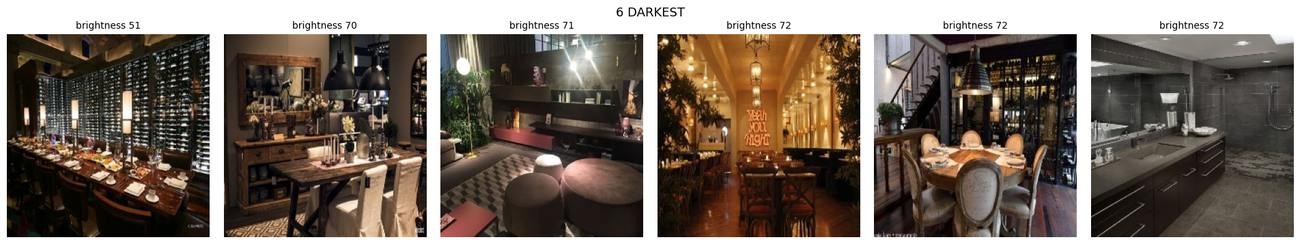

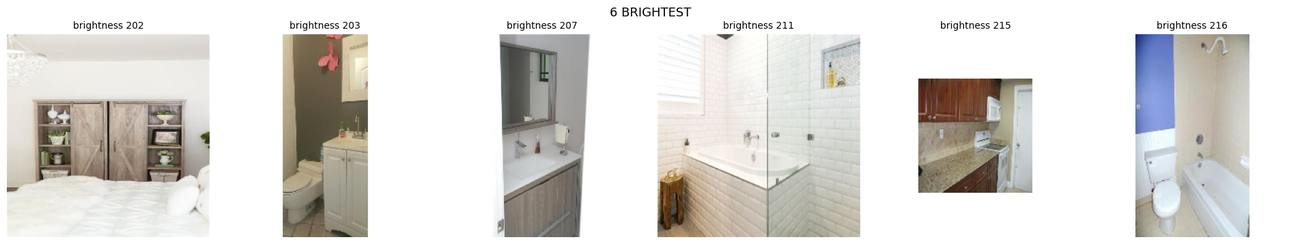

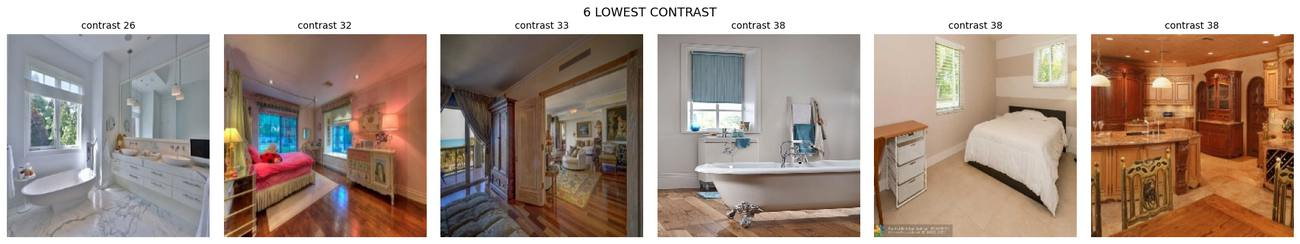

In [ ]:
# 7.3 Photos at the extremes of each measure
def show_row(rows, title, col):
    fig, axes = plt.subplots(1, len(rows), figsize=(3.2 * len(rows), 3.6))
    for ax, (_, r) in zip(axes, rows.iterrows()):
        ax.imshow(Image.open(r["path"]).convert("RGB"))
        ax.set_title(f"{col} {r[col]:.0f}", fontsize=10)
        ax.axis("off")
    plt.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

by_sharp = q.sort_values("sharpness")
by_bright = q.sort_values("brightness")
by_contrast = q.sort_values("contrast")

show_row(by_sharp.head(6),     "6 BLURRIEST (lowest sharpness)", "sharpness")
show_row(by_sharp.iloc[15:21], "Around the 5th percentile of sharpness: blurry or OK?", "sharpness")
show_row(by_bright.head(6),    "6 DARKEST", "brightness")
show_row(by_bright.tail(6),    "6 BRIGHTEST", "brightness")
show_row(by_contrast.head(6),  "6 LOWEST CONTRAST", "contrast")

**Distribution (300 random photos):** sharpness mostly 1,000–4,000 (median 2,166) with a small tail below 600; brightness 51–216, centred on 143; contrast mostly 40–80. The dataset is curated, so truly blurry, dark or washed-out photos are rare. The score below starts from the sample's 5th and 95th percentiles as thresholds.

Thresholds → sharpness ≥ 770, brightness 85–189, contrast ≥ 42, short side ≥ 200px


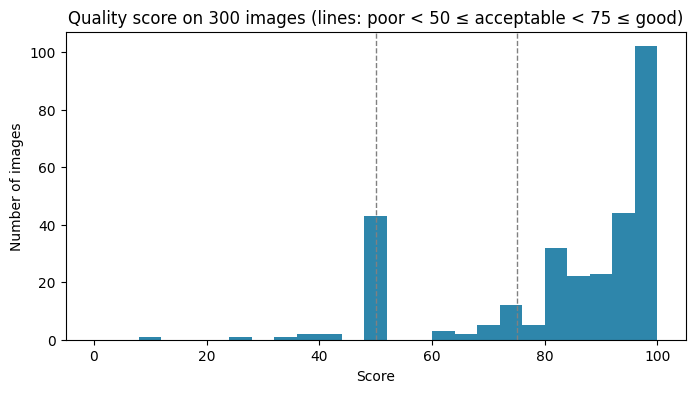

grade
good          230
poor           50
acceptable     20
Name: count, dtype: int64

Most common issues:
 issues
too dark                                14
too blurry                              10
too bright                               9
low contrast                             9
too blurry, too bright, low contrast     2
too bright, low contrast                 2
too blurry, too bright                   2
too blurry, low contrast                 1
too dark, low contrast                   1
Name: count, dtype: int64


In [ ]:
# 7.4 Combined 0–100 score
# ---------- Thresholds for this analysis: 5th / 95th percentiles of the 300-photo sample ----------
SHARPNESS_MIN  = q["sharpness"].quantile(0.05)
BRIGHTNESS_MIN = q["brightness"].quantile(0.05)
BRIGHTNESS_MAX = q["brightness"].quantile(0.95)
CONTRAST_MIN   = q["contrast"].quantile(0.05)
MIN_SHORT_SIDE = 200   # below this = too small. For real listings use ~600.

SHARPNESS_GOOD = q["sharpness"].median()   # a typical sharp photo scores 100
CONTRAST_GOOD  = q["contrast"].median()

WEIGHTS = {"sharpness": 0.55, "brightness": 0.30, "contrast": 0.15}

print(f"Thresholds → sharpness ≥ {SHARPNESS_MIN:.0f}, brightness {BRIGHTNESS_MIN:.0f}–{BRIGHTNESS_MAX:.0f}, "
      f"contrast ≥ {CONTRAST_MIN:.0f}, short side ≥ {MIN_SHORT_SIDE}px")

# ---------- The score ----------
def quality_score(path_or_image):
    m = photo_quality(path_or_image)

    # Each sub-score is 0–100. Exactly AT a threshold the sub-score is 50 (the pass/fail line).
    sharp = np.interp(np.log10(max(m["sharpness"], 1)),
                      [np.log10(SHARPNESS_MIN) - 0.3, np.log10(SHARPNESS_MIN), np.log10(SHARPNESS_GOOD)],
                      [0, 50, 100])
    bright = np.interp(m["brightness"],
                       [BRIGHTNESS_MIN - 30, BRIGHTNESS_MIN, BRIGHTNESS_MIN + 30,
                        BRIGHTNESS_MAX - 30, BRIGHTNESS_MAX, BRIGHTNESS_MAX + 30],
                       [0, 50, 100, 100, 50, 0])
    contrast = np.interp(m["contrast"], [CONTRAST_MIN - 15, CONTRAST_MIN, CONTRAST_GOOD], [0, 50, 100])

    score = (WEIGHTS["sharpness"] * sharp + WEIGHTS["brightness"] * bright + WEIGHTS["contrast"] * contrast)

    # Hard rules: failing any threshold means the photo needs attention
    issues = []
    if m["sharpness"] < SHARPNESS_MIN:              issues.append("too blurry")
    if m["brightness"] < BRIGHTNESS_MIN:            issues.append("too dark")
    if m["brightness"] > BRIGHTNESS_MAX:            issues.append("too bright")
    if m["contrast"] < CONTRAST_MIN:                issues.append("low contrast")
    if m["short_side"] < MIN_SHORT_SIDE:            issues.append("low resolution")
    if issues:
        score = min(score, 49)

    grade = "good" if score >= 75 else "acceptable" if score >= 50 else "poor"
    return {**m, "sharp_score": round(sharp), "bright_score": round(bright), "contrast_score": round(contrast),
            "score": round(score), "grade": grade, "issues": ", ".join(issues) or "none"}

# ---------- Apply to the 300-image sample ----------
scored = pd.DataFrame([quality_score(p) for p in tqdm(q["path"], desc="Scoring")])
scored.insert(0, "path", q["path"]); scored.insert(1, "label", q["label"])
scored.to_csv(OUT_DIR / "quality_scores_300.csv", index=False)

plt.figure(figsize=(8, 4))
plt.hist(scored["score"], bins=25, range=(0, 100), color="#2E86AB")
for x in (50, 75):
    plt.axvline(x, color="grey", linestyle="--", linewidth=1)
plt.title("Quality score on 300 images (lines: poor < 50 ≤ acceptable < 75 ≤ good)")
plt.xlabel("Score"); plt.ylabel("Number of images")
plt.savefig(OUT_DIR / "quality_score_hist.png", dpi=200, bbox_inches="tight")
plt.show()

print(scored["grade"].value_counts())
print("\nMost common issues:\n", scored.loc[scored["issues"] != "none", "issues"].value_counts())

**Scoring rule**
- Each measure becomes a 0–100 sub-score. Exactly at its threshold a sub-score is 50; a typical photo (the sample median) scores 100.
- **Score = 55% sharpness + 30% brightness + 15% contrast.** Blur counts most because it can't be fixed after the photo is taken.
- A photo that fails any threshold is capped at **49** and gets a reason ("too blurry", "too dark", "too bright", "low contrast", "low resolution").
- Grades: below 50 = poor, 50–74 = acceptable, 75+ = good.

With the percentile thresholds (sharpness ≥ 770, brightness 85–189, contrast ≥ 42), 50 of 300 photos (17%) grade poor. The sanity test checks that the score reacts to real damage; the best/worst grid shows what it gets wrong.

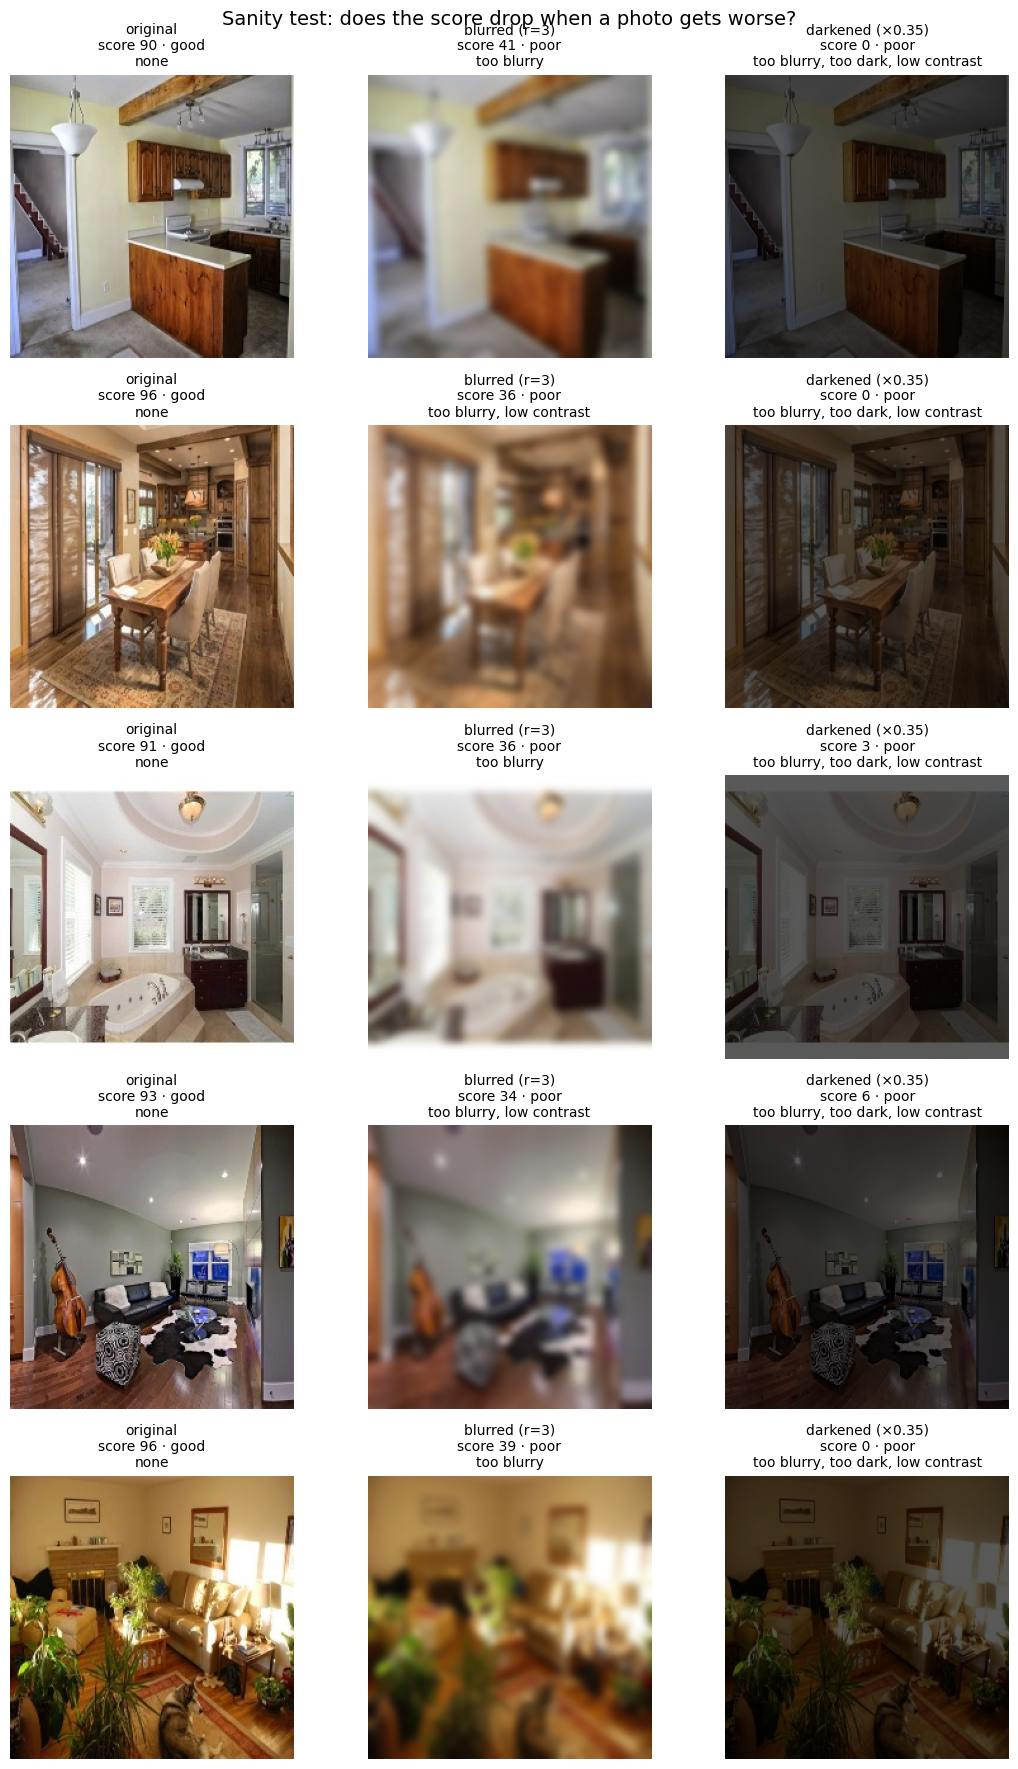

,image,original,blurred,darkened,blur_issue,dark_issue,blur_drop_ok,dark_drop_ok
0,din_924.jpg,90,41,0,too blurry,"too blurry, too dark, low contrast",True,True
1,din_1509.jpg,96,36,0,"too blurry, low contrast","too blurry, too dark, low contrast",True,True
2,bath_1148.jpg,91,36,3,too blurry,"too blurry, too dark, low contrast",True,True
3,living_708.jpg,93,34,6,"too blurry, low contrast","too blurry, too dark, low contrast",True,True
4,living_39.jpg,96,39,0,too blurry,"too blurry, too dark, low contrast",True,True


Score dropped in 10 of 10 degraded images.
Blurred flagged as poor: 5 of 5
Darkened flagged as poor: 5 of 5


In [ ]:
# 7.5 Sanity test: blur and darken good photos on purpose
from PIL import ImageFilter, ImageEnhance

BLUR_RADIUS = 3      # Gaussian blur strength (pixels)
DARKEN = 0.35        # keep 35% of the brightness

# Pick 5 photos the score already calls "good"
good = scored[scored["grade"] == "good"].sample(n=5, random_state=SEED)

rows, versions = [], []
for _, r in good.iterrows():
    original = Image.open(r["path"]).convert("RGB")
    blurred = original.filter(ImageFilter.GaussianBlur(radius=BLUR_RADIUS))
    darkened = ImageEnhance.Brightness(original).enhance(DARKEN)

    s_orig, s_blur, s_dark = quality_score(original), quality_score(blurred), quality_score(darkened)
    versions.append([(original, s_orig), (blurred, s_blur), (darkened, s_dark)])
    rows.append({
        "image": Path(r["path"]).name,
        "original": s_orig["score"], "blurred": s_blur["score"], "darkened": s_dark["score"],
        "blur_issue": s_blur["issues"], "dark_issue": s_dark["issues"],
        "blur_drop_ok": s_blur["score"] < s_orig["score"],
        "dark_drop_ok": s_dark["score"] < s_orig["score"],
    })

# ---------- Before/after grid ----------
fig, axes = plt.subplots(5, 3, figsize=(11, 18))
for row_axes, triple in zip(axes, versions):
    for ax, (img, s), name in zip(row_axes, triple, ["original", f"blurred (r={BLUR_RADIUS})", f"darkened (×{DARKEN})"]):
        ax.imshow(img)
        ax.set_title(f"{name}\nscore {s['score']} · {s['grade']}\n{s['issues']}", fontsize=10)
        ax.axis("off")
plt.suptitle("Sanity test: does the score drop when a photo gets worse?", fontsize=14)
plt.tight_layout()
plt.savefig(OUT_DIR / "quality_sanity_test.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------- Did it pass? ----------
test = pd.DataFrame(rows)
display(test)
n_pass = int(test["blur_drop_ok"].sum() + test["dark_drop_ok"].sum())
print(f"Score dropped in {n_pass} of {2 * len(test)} degraded images.")
print("Blurred flagged as poor:", int((test["blurred"] < 50).sum()), "of", len(test))
print("Darkened flagged as poor:", int((test["darkened"] < 50).sum()), "of", len(test))

**Sanity test:** five photos that scored 90–96 were blurred (radius 3) and darkened (35% brightness). Every score dropped: blurred versions fell to 34–41, darkened ones to 0–6, all graded poor with the right main reason.

One side effect: darkened photos were also flagged "too blurry". Sharpness is the variance of edge strength, and darkening shrinks edges too (variance falls with the square of brightness), so the measure mixes up dark and blurry. The verdict is right, but the reason given to a broker could mislead. Fix: normalise contrast before measuring sharpness.

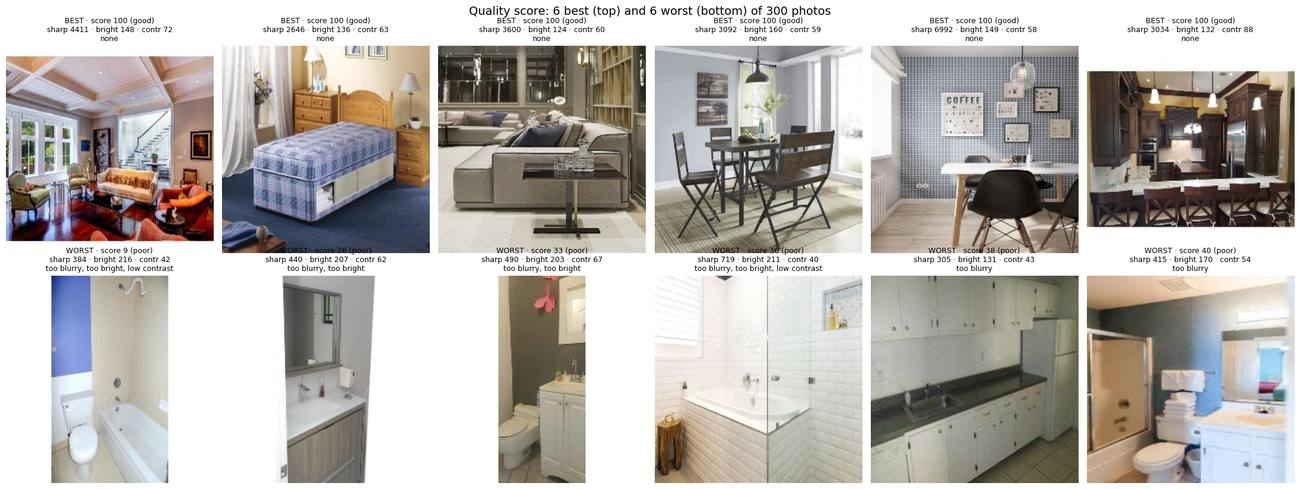

,group,label,score,grade,sharpness,brightness,contrast,issues
0,best,Livingroom,100,good,4411.0,148.0,72.0,none
1,best,Bedroom,100,good,2646.0,136.0,63.0,none
2,best,Livingroom,100,good,3600.0,124.0,60.0,none
3,best,Dinning,100,good,3092.0,160.0,59.0,none
4,best,Dinning,100,good,6992.0,149.0,58.0,none
5,best,Dinning,100,good,3034.0,132.0,88.0,none
299,worst,Bathroom,9,poor,384.0,216.0,42.0,"too blurry, too bright, low contrast"
298,worst,Bathroom,26,poor,440.0,207.0,62.0,"too blurry, too bright"
297,worst,Bathroom,33,poor,490.0,203.0,67.0,"too blurry, too bright"
296,worst,Bathroom,36,poor,719.0,211.0,40.0,"too blurry, too bright, low contrast"


In [ ]:
# 7.6 The 6 best and 6 worst photos by score
ranked = scored.sort_values("score", ascending=False).reset_index(drop=True)
best, worst = ranked.head(6), ranked.tail(6).iloc[::-1]   # worst shown from the very lowest upward

fig, axes = plt.subplots(2, 6, figsize=(22, 8.5))
for row_axes, group, name in [(axes[0], best, "BEST"), (axes[1], worst, "WORST")]:
    for ax, (_, r) in zip(row_axes, group.iterrows()):
        ax.imshow(Image.open(r["path"]).convert("RGB"))
        ax.set_title(f"{name} · score {r['score']} ({r['grade']})\n"
                     f"sharp {r['sharpness']:.0f} · bright {r['brightness']:.0f} · contr {r['contrast']:.0f}\n"
                     f"{r['issues']}", fontsize=9)
        ax.axis("off")
plt.suptitle("Quality score: 6 best (top) and 6 worst (bottom) of 300 photos", fontsize=14)
plt.tight_layout()
plt.savefig(OUT_DIR / "quality_best_worst.png", dpi=150, bbox_inches="tight")
plt.show()

display(pd.concat([best.assign(group="best"), worst.assign(group="worst")])
        [["group", "label", "score", "grade", "sharpness", "brightness", "contrast", "issues"]].round(0))

**Best and worst.** The best photos are bright, detailed rooms. Five of the six worst are **bathrooms** flagged "too bright" and "too blurry": white tiles and plain walls have few edges, so the Laplacian reads *plain* as *blurry*, and bright white rooms cross the 189 brightness limit. Those photos are fine, so the percentile thresholds are too strict for a curated dataset.

**Final thresholds (used by the app):** sharpness ≥ 500, brightness 60–210, contrast ≥ 30, short side ≥ 200 px, chosen by looking at the examples near each limit. They are meant to flag clearly bad photos only and should be re-checked on real broker uploads, which will include much worse photos than this dataset.

---
## 8. Amenity tags (zero-shot)

Buyers search for features. A photo can have several, so each tag is its own yes/no decision: the photo's CLIP embedding is compared with a "has it" prompt and a "doesn't have it" prompt (two wordings each, averaged), and CLIP's logit scale plus softmax turns the two similarities into P(yes). No labelled data is needed, and a new tag is just two new sentences.

The tags target the Egyptian market: pool and garden (compounds, villas), balcony, sea view (North Coast, Ain Sokhna), open kitchen, large windows, air conditioning, and unfinished walls (core-and-shell units).

In [ ]:
# 8.1 Tags: two 'has it' and two 'doesn't have it' prompts each
import json

# Each tag: a few ways to say "yes, it has it" and a few ways to say "no, it doesn't".
# Averaging several wordings (prompt ensembling, as in 3.6) makes each side more reliable.
TAGS = {
    "swimming pool": {
        "pos": ["a photo of a home with a swimming pool", "a swimming pool next to a house"],
        "neg": ["a photo of a home without a swimming pool", "a room in a house with no pool"],
    },
    "garden": {
        "pos": ["a photo of a home with a green garden", "a view of a garden with grass and plants"],
        "neg": ["a photo of a room with no garden", "an indoor room with no plants or grass outside"],
    },
    "balcony": {
        "pos": ["a photo of a room with a balcony", "a balcony or terrace attached to an apartment"],
        "neg": ["a photo of a room without a balcony", "a closed room with no balcony or terrace"],
    },
    "sea view": {
        "pos": ["a room with a view of the sea", "a window overlooking the ocean or sea"],
        "neg": ["a room with no sea view", "a window with a view of buildings or a street"],
    },
    "open kitchen": {
        "pos": ["an open-plan kitchen connected to the living room", "a kitchen open to the dining and living area"],
        "neg": ["a closed separate kitchen with walls", "a room with no kitchen"],
    },
    "large windows": {
        "pos": ["a bright room with large windows", "a room with floor-to-ceiling windows"],
        "neg": ["a room with small windows", "a dark room with no large windows"],
    },
    "air conditioning": {
        "pos": ["a room with an air conditioner on the wall", "a split air conditioning unit mounted on a wall"],
        "neg": ["a room with no air conditioner", "a wall with no air conditioning unit"],
    },
    "unfinished walls": {
        "pos": ["an unfinished room with bare concrete and brick walls", "a room under construction with no finishing"],
        "neg": ["a fully finished and painted room", "a finished room with painted walls and flooring"],
    },
}

def encode_side(prompts):
    """Average several prompts into one normalised vector."""
    e = encode_prompts(prompts)            # from 3.2: tokenise, encode, normalise
    e = e.mean(dim=0)
    return (e / e.norm()).cpu()

TAG_NAMES = list(TAGS)
tag_pos = torch.stack([encode_side(TAGS[t]["pos"]) for t in TAG_NAMES])   # (8, 512)
tag_neg = torch.stack([encode_side(TAGS[t]["neg"]) for t in TAG_NAMES])   # (8, 512)

print(f"{len(TAG_NAMES)} tags encoded:", TAG_NAMES)
print("Positive and negative embeddings:", tuple(tag_pos.shape), tuple(tag_neg.shape))

# Save the prompts so the demo (Step 11) uses exactly the same ones
with open(OUT_DIR / "tag_prompts.json", "w") as f:
    json.dump(TAGS, f, indent=2)


8 tags encoded: ['swimming pool', 'garden', 'balcony', 'sea view', 'open kitchen', 'large windows', 'air conditioning', 'unfinished walls']
Positive and negative embeddings: (8, 512) (8, 512)


In [ ]:
# 8.2 Tagging function; tag frequency per room type on the test set
TAG_THRESHOLD = 0.60                                  # tag a photo if P(yes) is above this
TAG_THRESHOLDS = {t: TAG_THRESHOLD for t in TAG_NAMES}  # one per tag, so you can tune each in 8.4
LOGIT_SCALE = model.logit_scale.exp().item()          # CLIP's own temperature (~100)

def tag_probs_from_emb(img_emb):
    """P(yes) for every tag, for a batch of normalised image embeddings. Returns (N images × N tags)."""
    s_pos = img_emb @ tag_pos.T                       # similarity to "has the feature"
    s_neg = img_emb @ tag_neg.T                       # similarity to "doesn't have it"
    pair = torch.stack([s_pos, s_neg], dim=-1) * LOGIT_SCALE
    return pair.softmax(dim=-1)[..., 0]               # probability of the "yes" side

def tags_from_probs(probs_row):
    """Turn one row of probabilities into a list of tags that pass their threshold."""
    return [t for t, p in zip(TAG_NAMES, probs_row.tolist()) if p >= TAG_THRESHOLDS[t]]

def tag_image(path_or_image):
    """Tag one photo (file path or PIL image). Returns {tag: probability} for passing tags, highest first."""
    img = path_or_image if isinstance(path_or_image, Image.Image) else Image.open(path_or_image)
    with torch.no_grad():
        e = model.encode_image(preprocess(img.convert("RGB")).unsqueeze(0).to(device))
        e = (e / e.norm(dim=-1, keepdim=True)).cpu()
    probs = tag_probs_from_emb(e)[0]
    found = {t: round(p, 2) for t, p in zip(TAG_NAMES, probs.tolist()) if p >= TAG_THRESHOLDS[t]}
    return dict(sorted(found.items(), key=lambda kv: -kv[1]))

# ---------- Run on the whole test set (embeddings already saved, so this is instant) ----------
test_tag_probs = tag_probs_from_emb(test_emb)                         # (788, 8)
tag_table = pd.DataFrame(test_tag_probs.numpy(), columns=TAG_NAMES).round(3)
tag_table.insert(0, "label", test_df["label"].values)
tag_table.insert(0, "path", test_df["path"].values)
tag_table["tags"] = [", ".join(tags_from_probs(r)) or "-" for r in test_tag_probs]
tag_table.to_csv(OUT_DIR / "test_tags.csv", index=False)

# How often is each tag given, overall and per room type?
freq = pd.DataFrame({t: (tag_table[t] >= TAG_THRESHOLDS[t]).groupby(tag_table["label"]).mean() * 100
                     for t in TAG_NAMES}).round(0)
freq.loc["ALL ROOMS"] = [(tag_table[t] >= TAG_THRESHOLDS[t]).mean() * 100 for t in TAG_NAMES]
print(f"% of test photos given each tag (threshold {TAG_THRESHOLD}):")
display(freq.astype(int))

# Quick test on one photo
print("Example:", Path(test_df.loc[0, "path"]).name, "→", tag_image(test_df.loc[0, "path"]))

% of test photos given each tag (threshold 0.6):


,swimming pool,garden,balcony,sea view,open kitchen,large windows,air conditioning,unfinished walls
label,,,,,,,,
Bathroom,0,0,0,3,1,42,11,4
Bedroom,0,0,0,4,1,65,8,5
Dinning,0,0,5,9,40,86,3,5
Kitchen,0,0,4,4,48,66,9,3
Livingroom,0,1,13,12,73,81,16,5
ALL ROOMS,0,0,5,6,35,71,9,4


Example: bed_185.jpg → {'large windows': 0.92}


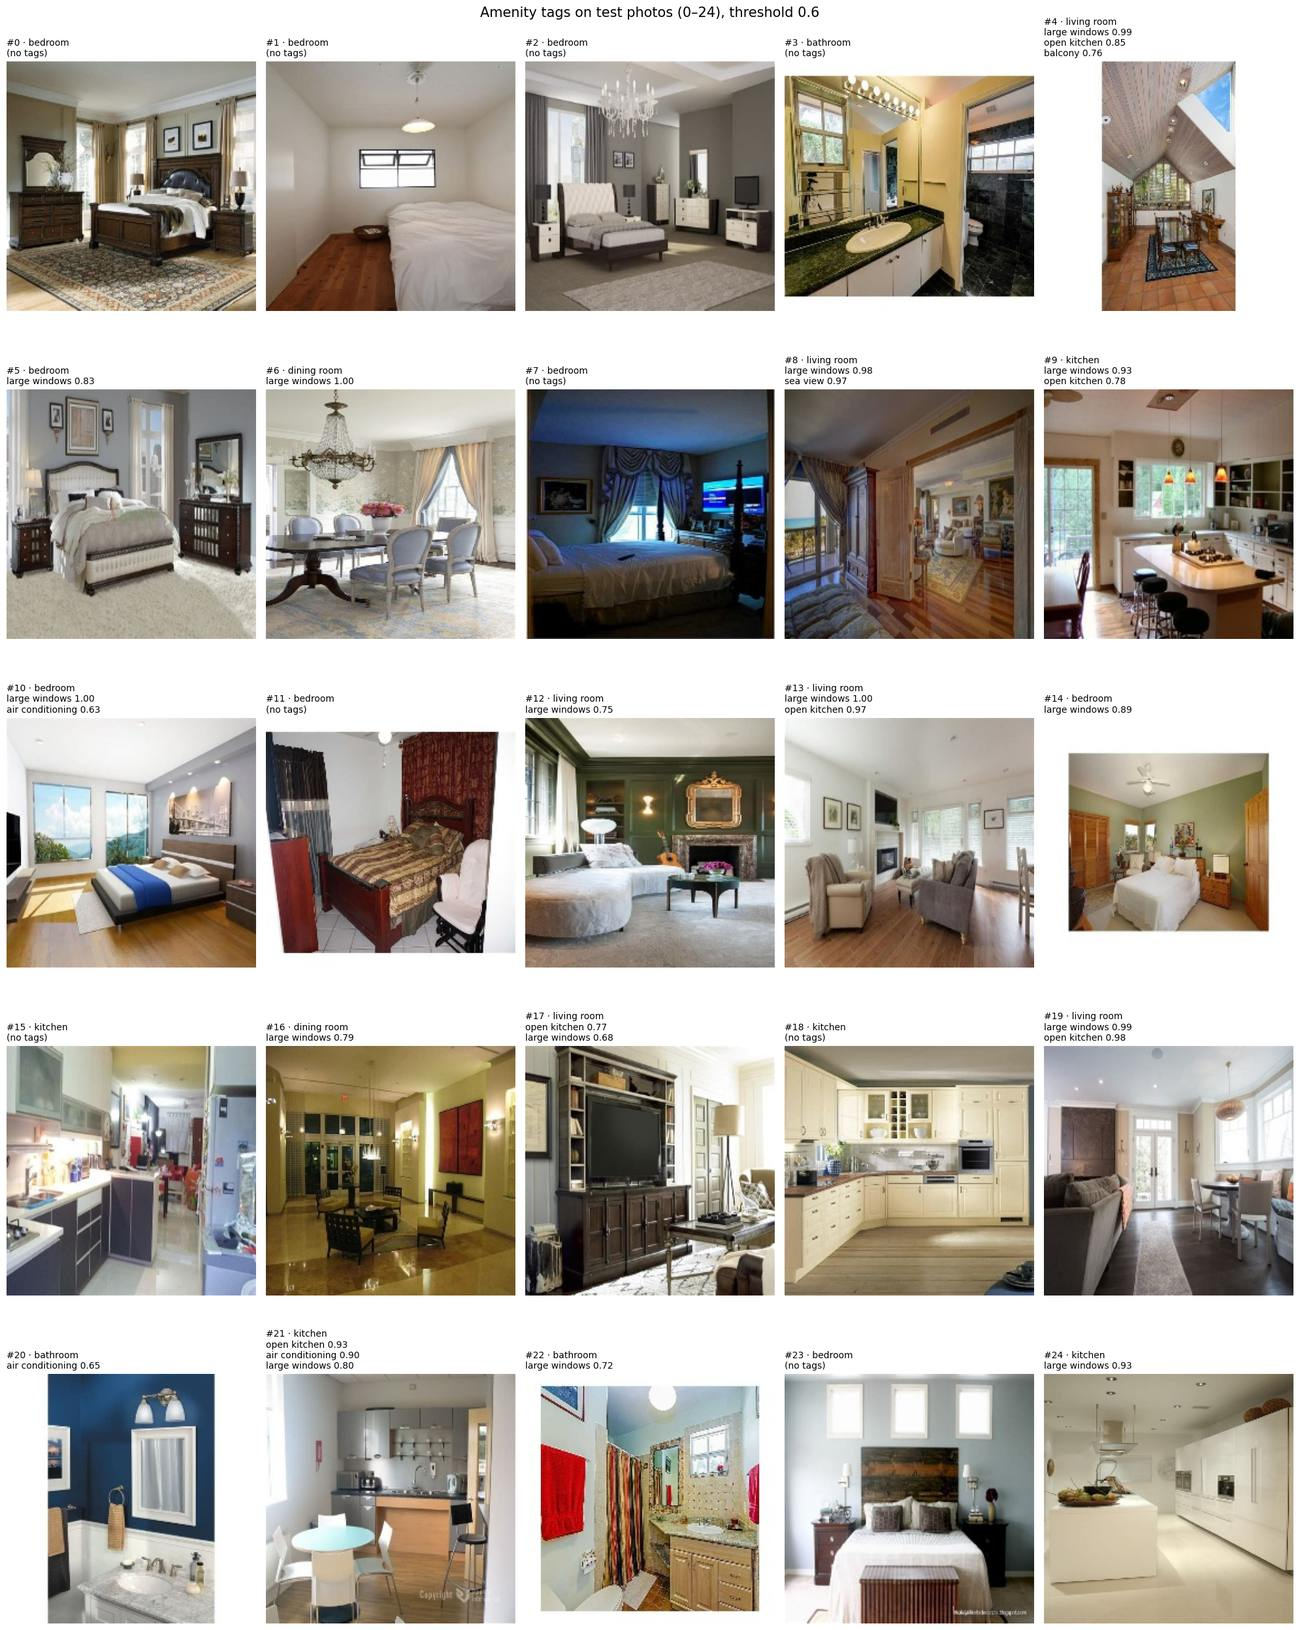

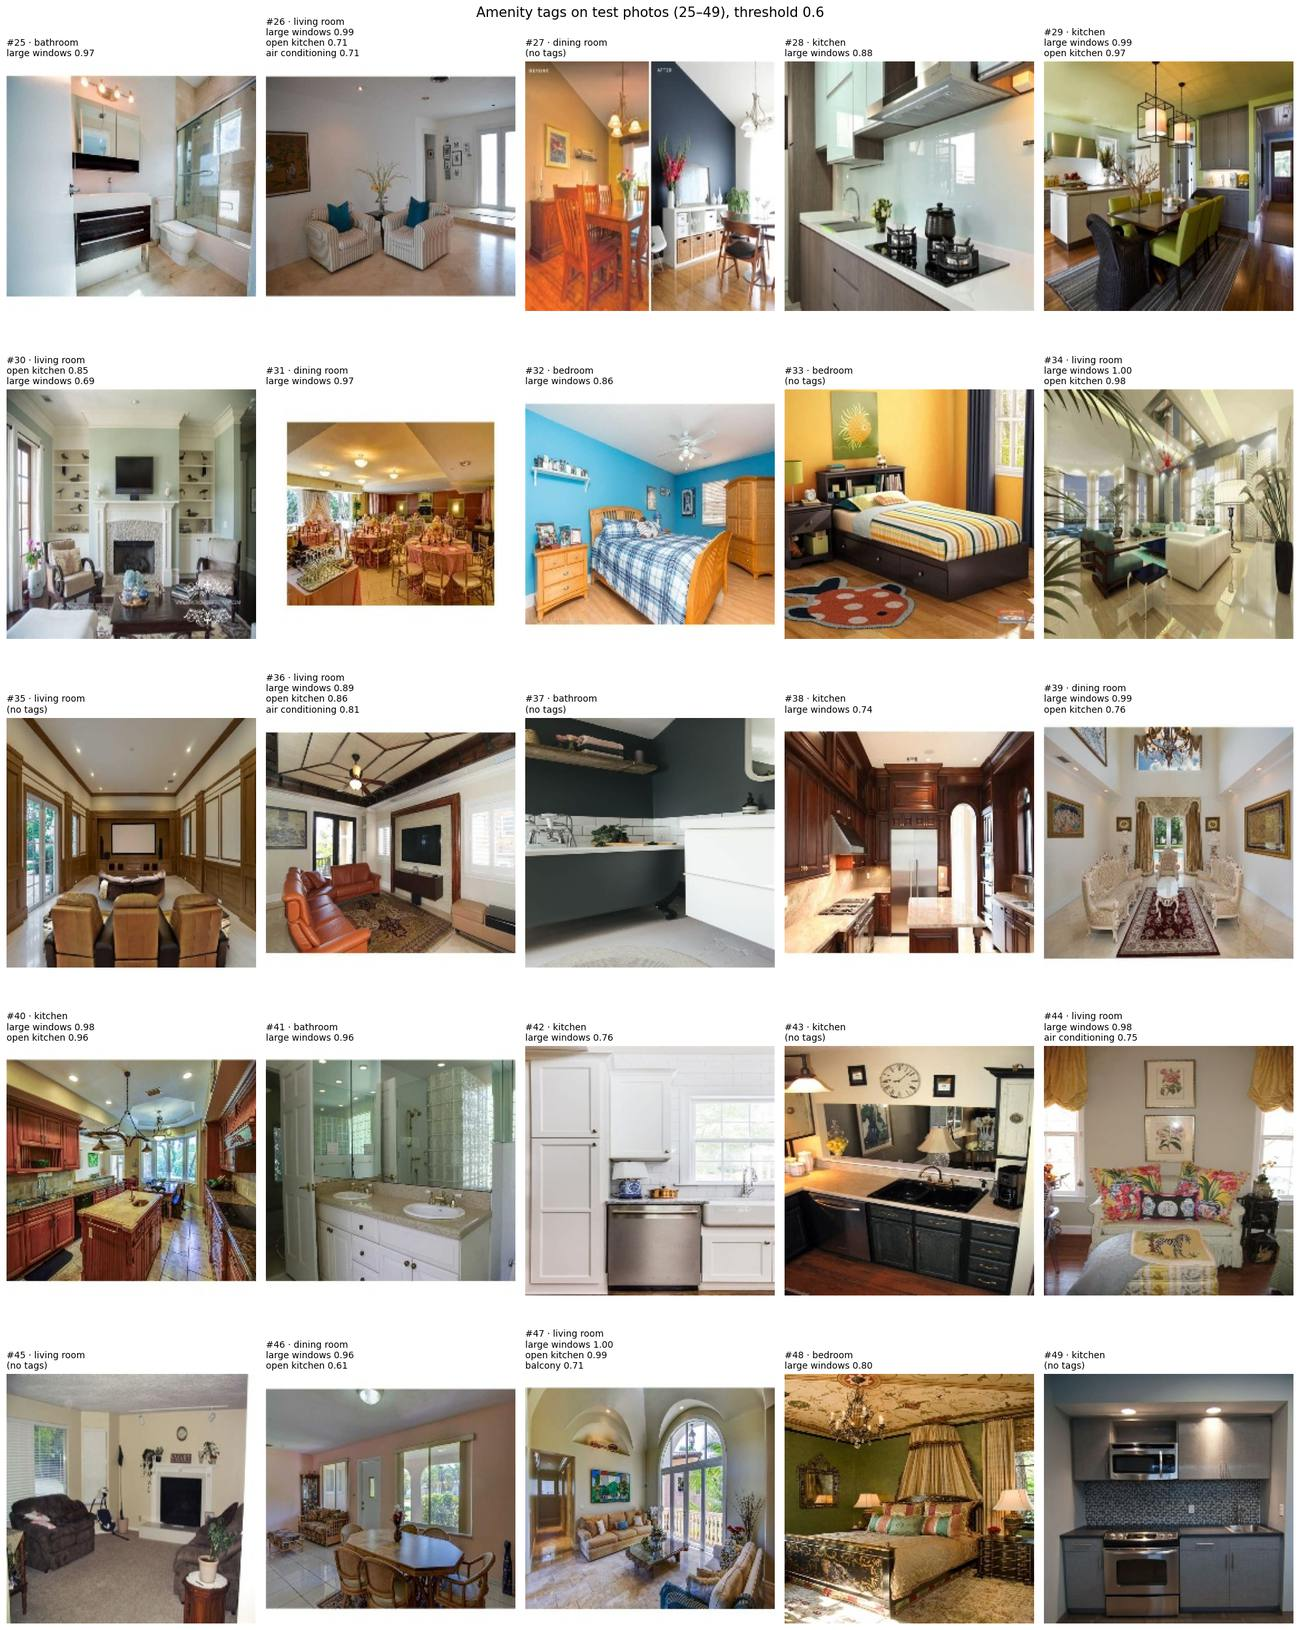

Photos with at least one tag: 34 of 50 | average tags per photo: 1.1
Tag counts in these 50:
large windows       33
open kitchen        15
air conditioning     6
balcony              2
sea view             1
Name: count, dtype: int64


In [ ]:
# 8.3 Tags on 50 random test photos
tag_sample = tag_table.sample(n=50, random_state=SEED).reset_index(drop=True)

def short_tags(row):
    """Tags that passed, with their probability, highest first, e.g. 'balcony 0.91, large windows 0.74'."""
    passed = [(t, row[t]) for t in TAG_NAMES if row[t] >= TAG_THRESHOLDS[t]]
    return "\n".join(f"{t} {p:.2f}" for t, p in sorted(passed, key=lambda x: -x[1])) or "(no tags)"

# Two pages of 25, so titles stay readable
for page in range(2):
    chunk = tag_sample.iloc[page * 25:(page + 1) * 25]
    fig, axes = plt.subplots(5, 5, figsize=(20, 26))
    for ax, (i, r) in zip(axes.flat, chunk.iterrows()):
        ax.imshow(Image.open(r["path"]).convert("RGB"))
        ax.set_title(f"#{i} · {CLASS_NAMES[r['label']]}\n{short_tags(r)}", fontsize=10, loc="left")
        ax.axis("off")
    plt.suptitle(f"Amenity tags on test photos ({page * 25}–{page * 25 + 24}), threshold {TAG_THRESHOLD}", fontsize=15)
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"tags_grid_{page + 1}.png", dpi=120, bbox_inches="tight")
    plt.show()

# Summary for these 50
n_tags = tag_sample["tags"].apply(lambda s: 0 if s == "-" else len(s.split(", ")))
print(f"Photos with at least one tag: {(n_tags > 0).sum()} of 50 | average tags per photo: {n_tags.mean():.1f}")
print("Tag counts in these 50:")
print(pd.Series([t for s in tag_sample["tags"] if s != "-" for t in s.split(", ")]).value_counts())

# Save the sample with an empty column per tag for your manual check in 8.4
check = tag_sample[["path", "label", "tags"]].copy()
check.to_csv(OUT_DIR / "tags_sample_50.csv", index_label="id")

**Findings (threshold 0.6 for every tag)**
- Rare outdoor features stay quiet on these interior photos: pool 0%, garden ~0%.
- Open kitchen follows room logic: living room 73%, kitchen 48%, dining 40%, bathroom and bedroom 1%. Balcony appears mostly in living rooms.
- Some tags fire too often: **large windows** on 71% of photos (it reacts to any bright room with a window), **sea view** on 6%, and **unfinished walls** on 3–5% of every room type although the dataset has only finished homes.

One threshold does not fit every tag, so the app uses per-tag thresholds: 0.8 for large windows, sea view and unfinished walls, 0.7 for open kitchen and air conditioning, 0.6 for the rest. The dataset has no tag labels, so tags were judged by eye on the grids above; measuring precision properly needs a few hundred labelled photos per tag.

---
## 9. Cover photo picker

A business rule on top of the models: every photo of a listing gets a room type (linear probe) and a quality score, and the cover is the photo with the highest **cover score = 70% quality + 30% room priority** (living room 1.0, kitchen 0.8, dining room 0.7, bedroom 0.6, bathroom 0.3). A photo graded *poor* is never chosen unless every photo is poor, in which case the picker also asks for better photos. Each choice comes with a one-line reason.

In [ ]:
# 9.1 Cover picker
# How much each room type is worth as a COVER photo (1.0 = best). Listings usually lead with the living area.
ROOM_PRIORITY = {"Livingroom": 1.0, "Kitchen": 0.8, "Dinning": 0.7, "Bedroom": 0.6, "Bathroom": 0.3}
QUALITY_WEIGHT, ROOM_WEIGHT = 0.7, 0.3   # cover score = 70% photo quality + 30% room priority

def embed_photos(images):
    """CLIP embeddings for a short list of PIL images (one listing = a handful of photos)."""
    batch = torch.stack([preprocess(img.convert("RGB")) for img in images]).to(device)
    with torch.no_grad():
        e = model.encode_image(batch)
    return (e / e.norm(dim=-1, keepdim=True)).cpu().numpy()

def choose_cover(photos):
    """Pick the best cover from one listing's photos (paths or PIL images).

    Returns (cover_index, reason, table) where table has one row per photo.
    """
    images = [p if isinstance(p, Image.Image) else Image.open(p).convert("RGB") for p in photos]

    # 1. Room type for every photo (linear probe on CLIP embeddings)
    proba = probe.predict_proba(embed_photos(images))
    rooms = probe.classes_[proba.argmax(axis=1)]
    room_conf = proba.max(axis=1)

    # 2. Quality for every photo
    quals = [quality_score(img) for img in images]

    # 3. Combine into one cover score
    table = pd.DataFrame({
        "photo": range(len(images)),
        "room": [CLASS_NAMES[r] for r in rooms],
        "room_conf": room_conf.round(2),
        "quality": [qs["score"] for qs in quals],
        "grade": [qs["grade"] for qs in quals],
        "issues": [qs["issues"] for qs in quals],
    })
    table["room_priority"] = [ROOM_PRIORITY[r] for r in rooms]
    table["cover_score"] = (QUALITY_WEIGHT * table["quality"] + ROOM_WEIGHT * 100 * table["room_priority"]).round(1)

    # 4. Never choose a "poor" photo, unless every photo is poor
    usable = table[table["grade"] != "poor"]
    pool = usable if len(usable) else table
    best = pool.sort_values("cover_score", ascending=False).iloc[0]
    i = int(best["photo"])

    reason = f"{best['room']} ({best['room_conf']:.0%} sure), quality {best['quality']} ({best['grade']})"
    if not len(usable):
        reason += " ⚠ all photos are poor quality: ask the broker for better ones"
    return i, reason, table.sort_values("cover_score", ascending=False).reset_index(drop=True)

# Quick test on 6 random test photos
demo_paths = test_df.sample(6, random_state=1)["path"].tolist()
idx, reason, table = choose_cover(demo_paths)
print("Cover: photo", idx, "→", reason)
display(table)

Cover: photo 0 → living room (75% sure), quality 100 (good)


,photo,room,room_conf,quality,grade,issues,room_priority,cover_score
0,0,living room,0.75,100,good,none,1.0,100.0
1,1,living room,0.51,100,good,none,1.0,100.0
2,2,living room,0.68,100,good,none,1.0,100.0
3,3,bedroom,0.83,100,good,none,0.6,88.0
4,5,bedroom,0.75,100,good,none,0.6,88.0
5,4,bedroom,0.47,77,good,none,0.6,71.9


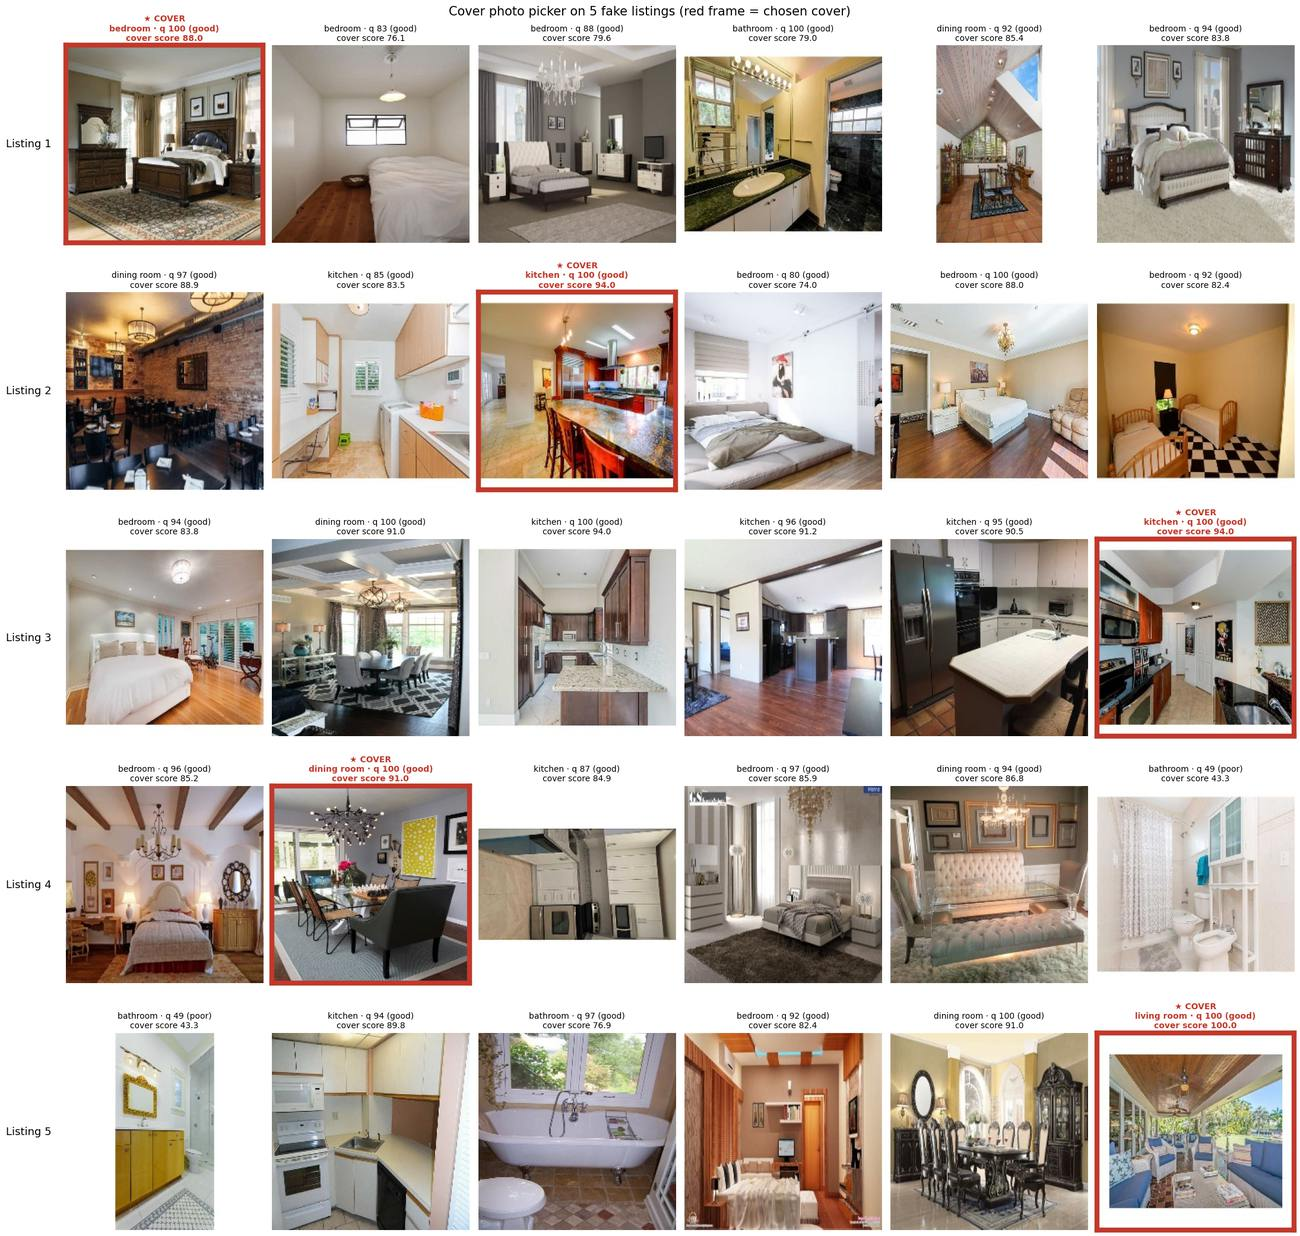

,listing,cover_photo,reason
0,1,0,"bedroom (80% sure), quality 100 (good)"
1,2,2,"kitchen (59% sure), quality 100 (good)"
2,3,5,"kitchen (60% sure), quality 100 (good)"
3,4,1,"dining room (76% sure), quality 100 (good)"
4,5,5,"living room (55% sure), quality 100 (good)"


In [ ]:
# 9.2 Five fake listings of six photos (red frame = chosen cover)
N_LISTINGS, PHOTOS_PER_LISTING = 5, 6
summary = []

fig, axes = plt.subplots(N_LISTINGS, PHOTOS_PER_LISTING, figsize=(22, 4.3 * N_LISTINGS))
for k in range(N_LISTINGS):
    paths = test_df.sample(PHOTOS_PER_LISTING, random_state=SEED + k)["path"].tolist()
    cover_i, reason, table = choose_cover(paths)
    info = table.set_index("photo")   # look up each photo's room/quality by its position

    for j, (ax, p) in enumerate(zip(axes[k], paths)):
        ax.imshow(Image.open(p).convert("RGB"))
        r = info.loc[j]
        is_cover = j == cover_i
        ax.set_title(("★ COVER\n" if is_cover else "\n") +
                     f"{r['room']} · q {r['quality']} ({r['grade']})\ncover score {r['cover_score']}",
                     fontsize=10, color="#C0392B" if is_cover else "black",
                     fontweight="bold" if is_cover else "normal")
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():                    # thick red frame around the cover
            spine.set_visible(is_cover)
            spine.set_color("#C0392B")
            spine.set_linewidth(6)
    axes[k, 0].set_ylabel(f"Listing {k + 1}", fontsize=13, rotation=0, labelpad=45, va="center")
    summary.append({"listing": k + 1, "cover_photo": cover_i, "reason": reason})

plt.suptitle("Cover photo picker on 5 fake listings (red frame = chosen cover)", fontsize=15)
plt.tight_layout()
plt.savefig(OUT_DIR / "cover_picker_listings.png", dpi=130, bbox_inches="tight")
plt.show()

cover_summary = pd.DataFrame(summary)
cover_summary.to_csv(OUT_DIR / "cover_picker_summary.csv", index=False)
display(cover_summary)

**Observations.** Every chosen cover scored 100 for quality, so room priority decided all five listings. On this curated dataset the quality score saturates for most photos (230 of 300 grade good), which leaves room type as the tie-breaker. Room confidence on the chosen covers is modest (55–80%), so the open-plan ambiguity from section 6 also affects which photo wins. The weights are business choices; on a real platform they would be tuned with an A/B test on clicks and leads.

---
## 10. Saving and reproducibility

Every setting the app needs (model names, class order, prompts, tag thresholds, quality thresholds and weights, cover rules) goes into one JSON file next to the trained probe and the embeddings. The second cell runs after **Runtime → Restart session** and loads everything from Drive only.

In [ ]:
# 10.1 Save every pipeline setting to one file and check all artifacts
# Final thresholds for the app (section 7: the percentile ones were too strict; section 8: one per tag)
SHARPNESS_MIN, BRIGHTNESS_MIN, BRIGHTNESS_MAX, CONTRAST_MIN = 500, 60, 210, 30
TAG_THRESHOLDS.update({"large windows": 0.8, "sea view": 0.8, "unfinished walls": 0.8,
                       "open kitchen": 0.7, "air conditioning": 0.7})

# 1. One settings file with everything the demo needs to rebuild the pipeline
config = {
    "clip_model": MODEL_NAME,
    "clip_pretrained": PRETRAINED,
    "classes": CLASSES,
    "class_names": CLASS_NAMES,
    "room_template": BEST_TEMPLATE,
    "probe_C": float(BEST_C),
    "tags": TAGS,
    "tag_thresholds": TAG_THRESHOLDS,
    "quality": {"sharpness_min": SHARPNESS_MIN, "brightness_min": BRIGHTNESS_MIN, "brightness_max": BRIGHTNESS_MAX,
                "contrast_min": CONTRAST_MIN, "min_short_side": MIN_SHORT_SIDE,
                "sharpness_good": float(SHARPNESS_GOOD), "contrast_good": float(CONTRAST_GOOD),
                "weights": WEIGHTS, "analysis_size": ANALYSIS_SIZE},
    "cover": {"room_priority": ROOM_PRIORITY, "quality_weight": QUALITY_WEIGHT, "room_weight": ROOM_WEIGHT},
}
with open(OUT_DIR / "prompts.json", "w") as f:
    json.dump(config, f, indent=2)

# 2. Checklist of everything the project produced
expected = {
    "Data splits":       ["train.csv", "val.csv", "test.csv", "images_clean.csv"],
    "Embeddings":        [f"embeddings/train_{MODEL_NAME}.npz", f"embeddings/val_{MODEL_NAME}.npz", f"embeddings/test_{MODEL_NAME}.npz"],
    "Models":            [f"linear_probe_{MODEL_NAME}.joblib", "resnet18_best.pt"],
    "Results tables":    ["results_test.csv", "experiments.csv", "classification_report_test.csv", "prompt_templates.csv"],
    "Figures":           ["class_counts.png", "confusion_matrix_test.png", "test_mistakes_grid.png", "resnet18_training_curves.png",
                          "quality_best_worst.png", "quality_sanity_test.png", "tags_grid_1.png", "cover_picker_listings.png"],
    "Settings and notes":["prompts.json", "flagged_images.csv"],
}

print("Folder:", OUT_DIR, "\n")
missing = []
for group, files in expected.items():
    print(group)
    for name in files:
        p = OUT_DIR / name
        if p.exists():
            print(f"   ✔ {name:42s} {p.stat().st_size / 1e6:6.2f} MB")
        else:
            print(f"   ✘ {name}")
            missing.append(name)
print(f"\n{'All files present ✔' if not missing else f'{len(missing)} missing: ' + ', '.join(missing)}")

Folder: /content/drive/MyDrive/proptech-vision/listinglens 

Data splits
   ✔ train.csv                                    0.52 MB
   ✔ val.csv                                      0.11 MB
   ✔ test.csv                                     0.11 MB
   ✔ images_clean.csv                             0.74 MB
Embeddings
   ✔ embeddings/train_ViT-B-32.npz                7.98 MB
   ✔ embeddings/val_ViT-B-32.npz                  1.71 MB
   ✔ embeddings/test_ViT-B-32.npz                 1.71 MB
Models
   ✔ linear_probe_ViT-B-32.joblib                 0.02 MB
   ✔ resnet18_best.pt                            44.80 MB
Results tables
   ✔ results_test.csv                             0.00 MB
   ✔ experiments.csv                              0.00 MB
   ✔ classification_report_test.csv               0.00 MB
   ✔ prompt_templates.csv                         0.00 MB
Figures
   ✔ class_counts.png                             0.07 MB
   ✔ confusion_matrix_test.png                    0.14 MB
   ✔ test_mistak

In [ ]:
# 10.2 Reproducibility check: after Runtime → Restart session, load everything from Drive only
!pip -q install open_clip_torch
import json, joblib, numpy as np, torch, open_clip
from pathlib import Path
from PIL import Image
from sklearn.metrics import f1_score
from google.colab import drive

drive.mount("/content/drive")
OUT_DIR = Path("/content/drive/MyDrive/proptech-vision/listinglens")
device = "cuda" if torch.cuda.is_available() else "cpu"

# 1. Load the settings, the model and the probe
cfg = json.load(open(OUT_DIR / "prompts.json"))
model, _, preprocess = open_clip.create_model_and_transforms(cfg["clip_model"], pretrained=cfg["clip_pretrained"])
model = model.to(device).eval()
probe = joblib.load(OUT_DIR / f"linear_probe_{cfg['clip_model']}.joblib")
print("Loaded:", cfg["clip_model"], "| probe classes:", list(probe.classes_))

# 2. Check 1: saved test embeddings → same test score as Step 6 (should be 0.946)
d = np.load(OUT_DIR / "embeddings" / f"test_{cfg['clip_model']}.npz", allow_pickle=True)
pred = probe.predict(d["emb"])
print(f"Test macro-F1 from saved files only: {f1_score(d['labels'], pred, average='macro'):.3f}")

# 3. Check 2: one prediction from a raw image (the full pipeline: image → CLIP → probe)
path = d["paths"][0]
if Path(path).exists():
    with torch.no_grad():
        e = model.encode_image(preprocess(Image.open(path).convert("RGB")).unsqueeze(0).to(device))
        e = (e / e.norm(dim=-1, keepdim=True)).cpu().numpy()
    p = probe.predict_proba(e)[0]
    room = probe.classes_[p.argmax()]
    print(f"{Path(path).name}: true = {d['labels'][0]}, predicted = {room} ({p.max():.0%} sure)")
else:
    print("Images not on disk (runtime was fully reset): run the Step 0 download cells to test a raw image.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded: ViT-B-32 | probe classes: ['Bathroom', 'Bedroom', 'Dinning', 'Kitchen', 'Livingroom']
Test macro-F1 from saved files only: 0.946
bed_185.jpg: true = Bedroom, predicted = Bedroom (73% sure)


After a restart, the saved probe and saved test embeddings reproduce the section 6 test macro-F1 (**0.946**), and a raw image goes through the full pipeline (image → CLIP → probe) correctly. Nothing depends on the notebook's memory.

---
## 11. Gradio demo

`analyze(image)` rebuilds the pipeline from the saved settings and returns room probabilities, the quality report, tags and a one-line summary. When the top two rooms are within 25 points, the summary shows both. The app has two tabs: **Analyse a photo** and **Choose a cover** (upload several photos of one listing). Phone photos are rotated according to their EXIF orientation.

The same app runs outside Colab from [`app/app.py`](../app/app.py); see the project README.

In [ ]:
# 11.1 analyze(): the full pipeline for one photo, rebuilt from the saved settings
# ---------- Setup: everything comes from Drive ----------
!pip -q install open_clip_torch gradio
import json, joblib, numpy as np, torch, open_clip, cv2
from pathlib import Path
from PIL import Image
from google.colab import drive

drive.mount("/content/drive")
OUT_DIR = Path("/content/drive/MyDrive/proptech-vision/listinglens")
device = "cuda" if torch.cuda.is_available() else "cpu"

cfg = json.load(open(OUT_DIR / "prompts.json"))
model, _, preprocess = open_clip.create_model_and_transforms(cfg["clip_model"], pretrained=cfg["clip_pretrained"])
tokenizer = open_clip.get_tokenizer(cfg["clip_model"])
model = model.to(device).eval()
probe = joblib.load(OUT_DIR / f"linear_probe_{cfg['clip_model']}.joblib")
LOGIT_SCALE = model.logit_scale.exp().item()

# ---------- Tag embeddings (from the saved prompts) ----------
def _encode_side(prompts):
    with torch.no_grad():
        e = model.encode_text(tokenizer(prompts).to(device))
        e = e / e.norm(dim=-1, keepdim=True)
        e = e.mean(dim=0)
        return (e / e.norm()).cpu()

TAG_NAMES = list(cfg["tags"])
tag_pos = torch.stack([_encode_side(cfg["tags"][t]["pos"]) for t in TAG_NAMES])
tag_neg = torch.stack([_encode_side(cfg["tags"][t]["neg"]) for t in TAG_NAMES])

# ---------- Photo quality (same rule as Step 7, settings from the file) ----------
Q = cfg["quality"]

def quality_score(img):
    img = img.convert("RGB")
    short_side = min(img.size)
    scale = Q["analysis_size"] / short_side
    small = img.resize((round(img.width * scale), round(img.height * scale)), Image.Resampling.LANCZOS)
    gray = cv2.cvtColor(np.array(small), cv2.COLOR_RGB2GRAY)
    sharpness, brightness, contrast = cv2.Laplacian(gray, cv2.CV_64F).var(), gray.mean(), gray.std()

    s = np.interp(np.log10(max(sharpness, 1)),
                  [np.log10(Q["sharpness_min"]) - 0.3, np.log10(Q["sharpness_min"]), np.log10(Q["sharpness_good"])], [0, 50, 100])
    b = np.interp(brightness, [Q["brightness_min"] - 30, Q["brightness_min"], Q["brightness_min"] + 30,
                               Q["brightness_max"] - 30, Q["brightness_max"], Q["brightness_max"] + 30], [0, 50, 100, 100, 50, 0])
    c = np.interp(contrast, [Q["contrast_min"] - 15, Q["contrast_min"], Q["contrast_good"]], [0, 50, 100])
    w = Q["weights"]
    score = w["sharpness"] * s + w["brightness"] * b + w["contrast"] * c

    issues = [msg for cond, msg in [
        (sharpness < Q["sharpness_min"], "too blurry"), (brightness < Q["brightness_min"], "too dark"),
        (brightness > Q["brightness_max"], "too bright"), (contrast < Q["contrast_min"], "low contrast"),
        (short_side < Q["min_short_side"], "low resolution")] if cond]
    if issues:
        score = min(score, 49)
    grade = "good" if score >= 75 else "acceptable" if score >= 50 else "poor"
    return {"score": int(round(score)), "grade": grade, "issues": issues or ["none"],
            "sharpness": round(float(sharpness)), "brightness": round(float(brightness)),
            "contrast": round(float(contrast)), "size": f"{img.width}×{img.height}"}

# ---------- The one function the demo calls ----------
def analyze(image):
    """Analyse one listing photo (PIL image).

    Returns:
        rooms   - {room name: probability} for all 5 rooms
        quality - score, grade, issues and raw measures
        tags    - {tag: probability} for tags above their threshold
        summary - one readable sentence
    """
    if image is None:
        return {}, {}, {}, "Upload a photo to analyse it."
    image = image.convert("RGB")

    # One CLIP embedding, used for BOTH room type and tags
    with torch.no_grad():
        e = model.encode_image(preprocess(image).unsqueeze(0).to(device))
        e = (e / e.norm(dim=-1, keepdim=True)).cpu()

    # Room type (linear probe)
    p = probe.predict_proba(e.numpy())[0]
    rooms = {cfg["class_names"][c]: float(prob) for c, prob in zip(probe.classes_, p)}
    top_room, top_p = max(rooms.items(), key=lambda kv: kv[1])

    # Show two rooms when the model is unsure (the open-plan fix from Step 6)
    second_room, second_p = sorted(rooms.items(), key=lambda kv: -kv[1])[1]
    room_text = f"{top_room} / {second_room}" if top_p - second_p < 0.25 else top_room

    # Tags (yes vs no prompt per tag)
    pair = torch.stack([e @ tag_pos.T, e @ tag_neg.T], dim=-1) * LOGIT_SCALE
    yes = pair.softmax(dim=-1)[0, :, 0].tolist()
    tags = {t: round(y, 2) for t, y in zip(TAG_NAMES, yes) if y >= cfg["tag_thresholds"][t]}
    tags = dict(sorted(tags.items(), key=lambda kv: -kv[1]))

    # Quality
    quality = quality_score(image)

    summary = (f"**{room_text}** ({top_p:.0%} sure) · quality **{quality['score']}/100 ({quality['grade']})**"
               + ("" if quality["issues"] == ["none"] else f" — {', '.join(quality['issues'])}")
               + (f" · tags: {', '.join(tags)}" if tags else " · no amenity tags"))
    return rooms, quality, tags, summary

# ---------- Test on 2 photos from the test set ----------
import pandas as pd
test_df = pd.read_csv(OUT_DIR / "test.csv")
for path in test_df["path"].head(2):
    if Path(path).exists():
        rooms, quality, tags, summary = analyze(Image.open(path))
        print(Path(path).name, "|", summary.replace("**", ""))
    else:
        print("Dataset not on disk: run Step 0 to test with dataset photos (your own photos will still work).")
        break

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
bed_185.jpg | bedroom (73% sure) · quality 77/100 (good) · tags: large windows
bed_23.jpg | bedroom (59% sure) · quality 92/100 (good) · tags: large windows


In [ ]:
# 11.2 Gradio app: 'Analyse a photo' and 'Choose a cover' tabs
import gradio as gr
import shutil
from PIL import ImageOps

# ---------- Example photos: one per room type, copied to a short local path ----------
EX_DIR = Path("/content/examples")
EX_DIR.mkdir(exist_ok=True)
examples = []
for label in ["Livingroom", "Kitchen", "Bedroom", "Bathroom"]:
    src = Path(test_df[test_df["label"] == label].iloc[0]["path"])
    if src.exists():
        dst = EX_DIR / src.name
        shutil.copy(src, dst)
        examples.append([str(dst)])

def fix_orientation(img):
    """Phone photos store rotation in EXIF; without this, portrait photos can appear sideways."""
    return ImageOps.exif_transpose(img) if img is not None else None

# ---------- Tab 1: analyse one photo ----------
def analyze_ui(image):
    rooms, quality, tags, summary = analyze(fix_orientation(image))
    return summary, rooms, tags, quality

# ---------- Tab 2: choose a cover from several photos ----------
FOLDER_OF = {nice: folder for folder, nice in cfg["class_names"].items()}  # "living room" → "Livingroom"
C = cfg["cover"]

def pick_cover(files):
    if not files:
        return [], "Upload 2–10 photos of the same listing."
    paths = [f if isinstance(f, str) else f.name for f in files]
    rows = []
    for p in paths:
        img = fix_orientation(Image.open(p)).convert("RGB")
        rooms, quality, _, _ = analyze(img)
        room = max(rooms, key=rooms.get)
        priority = C["room_priority"][FOLDER_OF[room]]
        rows.append({"img": img, "room": room, "conf": rooms[room], "q": quality,
                     "cover_score": C["quality_weight"] * quality["score"] + C["room_weight"] * 100 * priority})

    usable = [r for r in rows if r["q"]["grade"] != "poor"] or rows   # never pick a poor photo unless all are poor
    best = max(usable, key=lambda r: r["cover_score"])

    ordered = [best] + sorted([r for r in rows if r is not best], key=lambda r: -r["cover_score"])
    gallery = [(r["img"], ("★ COVER · " if r is best else "") +
                f"{r['room']} · quality {r['q']['score']} ({r['q']['grade']})") for r in ordered]
    reason = (f"**Cover:** {best['room']} ({best['conf']:.0%} sure), quality {best['q']['score']}/100 ({best['q']['grade']}).")
    if all(r["q"]["grade"] == "poor" for r in rows):
        reason += "\n\n⚠ All photos are poor quality. Ask the broker for better photos."
    return gallery, reason

# ---------- Layout ----------
with gr.Blocks(title="ListingLens") as demo:
    gr.Markdown("# ListingLens\nRoom type, photo quality and amenity tags for real-estate listing photos. "
                "Built with CLIP ViT-B-32 + a linear probe (test macro-F1 0.946).")

    with gr.Tab("Analyse a photo"):
        with gr.Row():
            with gr.Column(scale=1):
                inp = gr.Image(type="pil", label="Listing photo", height=360)
                btn = gr.Button("Analyse", variant="primary")
                gr.Examples(examples=examples, inputs=inp)
            with gr.Column(scale=1):
                summary_out = gr.Markdown()
                rooms_out = gr.Label(num_top_classes=5, label="Room type")
                tags_out = gr.Label(label="Amenity tags (only those above their threshold)")
                quality_out = gr.JSON(label="Photo quality")
        btn.click(analyze_ui, inputs=inp, outputs=[summary_out, rooms_out, tags_out, quality_out])
        inp.upload(analyze_ui, inputs=inp, outputs=[summary_out, rooms_out, tags_out, quality_out])

    with gr.Tab("Choose a cover"):
        files_in = gr.File(file_count="multiple", file_types=["image"], label="Photos of one listing (2–10)")
        cover_btn = gr.Button("Choose cover", variant="primary")
        reason_out = gr.Markdown()
        gallery_out = gr.Gallery(label="Ranked photos (cover first)", columns=4, height="auto")
        cover_btn.click(pick_cover, inputs=files_in, outputs=[gallery_out, reason_out])

    gr.Markdown("Limitations: trained on 5,250 small (224×224) photos of mostly Western homes; "
                "tags are zero-shot and were checked by eye only. Thresholds need tuning on real listing photos.")

demo.launch(share=True)

---
## Conclusions

1. **Start from the strongest pretrained model and train as little as possible.** With ~3,700 labelled photos, frozen CLIP + logistic regression (0.946 test macro-F1, 2 s of training) matches a model 3× larger and beats a fine-tuned ResNet-18 by ~5 points.
2. **Don't chase noise.** The top four models are within 6 test images of each other; the cheapest one was kept, chosen on validation.
3. **The data sets the ceiling.** Remaining errors are mostly open-plan photos showing two rooms, and photos stored twice with different labels. Multi-label room tags and a re-labelling pass would help more than a bigger model.
4. **Simple, explainable rules go a long way** for photo quality and cover selection, as long as they are tested (10/10 damaged photos flagged) and their failure modes are known (plain bright rooms read as "blurry").

**Limitations**
- Small, curated dataset of 224 × 224 photos of mostly Western homes. Real Egyptian listings (larger photos, 3D renders of off-plan units, unfinished core-and-shell rooms) need their own test set.
- No exterior, floor-plan or "living + dining" classes.
- Amenity tags were checked by eye only; no labelled precision or recall.
- Quality thresholds were chosen on this dataset; sharpness confuses plain surfaces and darkness with blur.

**Next steps**
- Render-vs-real-photo detector (off-plan listings are mostly 3D renders).
- Multi-label room tags on a re-labelled subset.
- Contrast-normalised sharpness, and a learned quality model (MUSIQ) as a comparison.
- Host the demo on Hugging Face Spaces.

---
## Appendix: key terms

| Word | Meaning |
|---|---|
| **Image** | To a computer, a colour image is a grid of numbers with shape *height × width × 3*. The 3 numbers per pixel are red, green and blue, each from 0 to 255. |
| **Class / label** | The correct answer for an image, for example `Kitchen`. |
| **Classification** | Predicting the class of an image. |
| **Training set** | Images the model learns from. |
| **Validation set** | Images you use to make choices (which model, which settings). |
| **Test set** | Images you look at **only once, at the end**, to report the final score honestly. |
| **Pretrained model** | A model someone already trained on millions of images. You reuse what it learned. |
| **Embedding (feature vector)** | A list of numbers (for example 512 of them) that a model produces to describe an image. Similar images get similar embeddings. |
| **CLIP** | A model trained on hundreds of millions to billions of image–caption pairs. It turns images **and** sentences into embeddings in the same space, so you can compare a photo with a sentence like "a photo of a kitchen". |
| **Zero-shot** | Classifying without training on your data at all. |
| **Linear probe** | Keep the pretrained model frozen, take its embeddings, and train only a simple classifier (like logistic regression) on top. |
| **Fine-tuning** | Continue training the pretrained model itself on your data. |
| **Accuracy** | Fraction of images predicted correctly. |
| **Precision / Recall / F1** | Per-class scores. Precision: of the images I called "Kitchen", how many were kitchens? Recall: of all real kitchens, how many did I find? F1 combines both. |
| **Macro-F1** | The average F1 over all classes, each class counted equally. Better than accuracy when classes have different sizes. |
| **Confusion matrix** | A table showing, for each real class, what the model predicted. It shows *which* classes get mixed up. |
| **GPU** | Hardware that makes deep learning much faster. Colab gives you a free T4 GPU. |